# ECG Heartbeat Classification Using Multimodal Fusion — Training (GAF & RP)

Notebook **training** hasil refactor dari `01_replikasi (1).ipynb`.

| Aturan | Keterangan |
|---|---|
| Sumber data | Membaca artifact HDF5 yang **sudah ada** di Google Drive. Notebook ini **tidak menghitung** GAF/RP. |
| GAF | `hb_data_mit_bih_balanced_3_fixed.hdf5`. File `hb_data_mit_bih_balanced_3.hdf5` rusak (NaN/Inf) dan **tidak dipakai**. |
| Preprocessing | Ada di `00_preprocessing.ipynb`. **Tidak perlu dijalankan ulang** karena artifact sudah tersimpan. |
| Restart runtime | Aman. Jalankan dari atas; setiap cell hanya bergantung pada cell di atasnya. |
| Full training | **Tidak otomatis**, bahkan pada Run All. Section 9 dan 11 terkunci flag `RUN_GAF_FULL` / `RUN_RP_FULL = False`; ubah ke `True` setelah smoke test diperiksa. |
| API | Satu `build_baseline()`, satu `Dataset_Hdf5`, satu `train()`, satu nama device: `DEVICE`. |

---

**Lanjutan replikasi (Section 13–22)**: MTF, MIF, MFF (GFN + SVM, dan varian repositori), evaluasi akhir, perbandingan dengan paper.
Semua tahap baru **resumable** (artifact valid → LOAD, bukan dibuat ulang) dan terkunci flag `RUN_* = False`.
GAF/RP **tidak dilatih ulang**: Section 12 dan seterusnya membaca history/checkpoint yang sudah tersimpan di Drive.

# 1. Environment

In [ ]:
import math
import os
import random

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from google.colab import drive
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from torch.utils.data import DataLoader, Dataset
from torchvision.models import ResNet18_Weights, resnet18

drive.mount("/content/drive")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("DEVICE      :", DEVICE)

if DEVICE.type == "cuda":
    print("GPU         :", torch.cuda.get_device_name(0))
else:
    print("PERINGATAN: GPU tidak aktif. Runtime > Change runtime type > GPU.")


def set_seed(seed):
    """Seed global + cuDNN deterministik (sama dengan notebook lama, cell 24)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


Mounted at /content/drive
PyTorch     : 2.14.1+cu130
Torchvision : 0.29.1+cu130
DEVICE      : cuda
GPU         : Tesla T4


# 2. Configuration / Paths

In [ ]:
BASE_DIR = "/content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion"

FEATURES_DIR = os.path.join(BASE_DIR, "features")
HDF5_DIR = os.path.join(BASE_DIR, "hdf5")
CKPT_DIR = os.path.join(BASE_DIR, "checkpoints")
RESULTS_DIR = os.path.join(BASE_DIR, "outputs", "results")

# GAF utama = versi FIXED.
# JANGAN gunakan hb_data_mit_bih_balanced_3.hdf5 (terbukti mengandung NaN/Inf).
GAF_H5 = os.path.join(HDF5_DIR, "hb_data_mit_bih_balanced_3_fixed.hdf5")
RP_H5 = os.path.join(HDF5_DIR, "hb_data_mit_bih_balanced_rp.hdf5")

FEATURE_PATHS = {
    name: os.path.join(FEATURES_DIR, name)
    for name in ("X_train_smote.npy", "y_train_smote.npy", "X_test.npy", "y_test.npy")
}

# Dimensi artifact yang sudah divalidasi
N_TRAIN = 152471  # 87554 asli + SMOTE
N_TEST = 21892
SMOTE_TARGETS = {1: 30000, 2: 20000, 3: 20000, 4: 10000}

FEATURE_SHAPES = {
    "X_train_smote.npy": (N_TRAIN, 187),
    "y_train_smote.npy": (N_TRAIN,),
    "X_test.npy": (N_TEST, 187),
    "y_test.npy": (N_TEST,),
}
HDF5_SPEC = {
    "x_train": ((N_TRAIN, 224, 224), np.float32),
    "y_train": ((N_TRAIN,), np.int32),
    "x_test": ((N_TEST, 224, 224), np.float32),
    "y_test": ((N_TEST,), np.int32),
}

# Validasi pixel: default = sampel blok tersebar merata + blok TERAKHIR
# (sampel sintetik SMOTE ada di ujung array). FULL_SCAN=True membaca seluruh
# file (~30 GB per file HDF5, lambat dari Drive).
FULL_SCAN = False
SCAN_BLOCK = 128
SCAN_N_BLOCKS = 8

BATCH_SIZE = 64
SEED = 42

os.makedirs(CKPT_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)
set_seed(SEED)

print("GAF_H5 :", GAF_H5)
print("RP_H5  :", RP_H5)
print("CKPT   :", CKPT_DIR)
print("RESULTS:", RESULTS_DIR)


GAF_H5 : /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/hdf5/hb_data_mit_bih_balanced_3_fixed.hdf5
RP_H5  : /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/hdf5/hb_data_mit_bih_balanced_rp.hdf5
CKPT   : /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/checkpoints
RESULTS: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/outputs/results


# 3. Artifact Validation

Memeriksa: file ada, shape, dtype, NaN, Inf, range, dan label. Jika ada yang gagal, cell **menghentikan Run All**.
Jika artifact tidak ditemukan, jalankan `00_preprocessing.ipynb` terlebih dahulu.

In [ ]:
def _scan_starts(n):
    if FULL_SCAN:
        return list(range(0, n, SCAN_BLOCK))
    last = max(n - SCAN_BLOCK, 0)
    return sorted(set(np.linspace(0, last, SCAN_N_BLOCKS, dtype=int).tolist()))


def _scan_images(ds):
    n_read = n_nan = n_inf = 0
    lo, hi = np.inf, -np.inf
    for start in _scan_starts(len(ds)):
        block = ds[start:start + SCAN_BLOCK]
        n_read += len(block)
        n_nan += int(np.isnan(block).sum())
        n_inf += int(np.isinf(block).sum())
        finite = block[np.isfinite(block)]
        if finite.size:
            lo = min(lo, float(finite.min()))
            hi = max(hi, float(finite.max()))
    return n_read, n_nan, n_inf, lo, hi


def validate_hdf5(path, name, y_train_ref, y_test_ref):
    """Validasi satu file HDF5. Mengembalikan list masalah (kosong = valid)."""
    problems = []
    expected_counts = {0: N_TRAIN - sum(SMOTE_TARGETS.values()), **SMOTE_TARGETS}
    print(f"\n[{name}] {os.path.basename(path)}")

    with h5py.File(path, "r") as f:
        for key, (shape, dtype) in HDF5_SPEC.items():
            if key not in f:
                problems.append(f"{name}: dataset '{key}' tidak ada")
                continue

            ds = f[key]
            line = f"  {key:8s} shape={ds.shape} dtype={ds.dtype}"

            if ds.shape != shape:
                problems.append(f"{name}/{key}: shape {ds.shape} != {shape}")
            if ds.dtype != dtype:
                problems.append(f"{name}/{key}: dtype {ds.dtype} != {np.dtype(dtype).name}")

            if key.startswith("x_") and ds.shape == shape:
                n_read, n_nan, n_inf, lo, hi = _scan_images(ds)
                line += f" | {n_read} sampel: NaN={n_nan} Inf={n_inf} min={lo:.4f} max={hi:.4f}"
                if n_nan or n_inf:
                    problems.append(f"{name}/{key}: NaN={n_nan}, Inf={n_inf}")
                if lo < -1.01 or hi > 1.01:
                    problems.append(f"{name}/{key}: range [{lo:.4f}, {hi:.4f}] di luar [-1, 1]")
            print(line)

        if all(k in f for k in HDF5_SPEC):
            y_train, y_test = f["y_train"][:], f["y_test"][:]

            classes, counts = np.unique(y_train, return_counts=True)
            got_counts = dict(zip(classes.tolist(), counts.tolist()))
            if got_counts != expected_counts:
                problems.append(f"{name}/y_train: distribusi {got_counts} != {expected_counts}")
            if not set(np.unique(y_test).tolist()) <= {0, 1, 2, 3, 4}:
                problems.append(f"{name}/y_test: label di luar 0..4")
            if not np.array_equal(y_train, y_train_ref):
                problems.append(f"{name}/y_train: tidak sama dengan features/y_train_smote.npy")
            if not np.array_equal(y_test, y_test_ref):
                problems.append(f"{name}/y_test: tidak sama dengan features/y_test.npy")
            print(f"  label    train={got_counts}")

    return problems


# --- 1) file ada?
missing = [p for p in [GAF_H5, RP_H5, *FEATURE_PATHS.values()] if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(
        "Artifact berikut TIDAK ditemukan:\n  - " + "\n  - ".join(missing)
        + "\n\nPreprocessing harus dijalankan terlebih dahulu: jalankan 00_preprocessing.ipynb."
        + "\nJika file seharusnya ada, pastikan Drive ter-mount dan BASE_DIR (Section 2) benar."
    )

problems = []

# --- 2) features/*.npy
print("[features]")
for fname, shape in FEATURE_SHAPES.items():
    arr = np.load(FEATURE_PATHS[fname], mmap_mode="r")
    print(f"  {fname:20s} shape={arr.shape} dtype={arr.dtype}")
    if arr.shape != shape:
        problems.append(f"features/{fname}: shape {arr.shape} != {shape}")
    if fname.startswith("X_") and not np.isfinite(arr).all():
        problems.append(f"features/{fname}: mengandung NaN/Inf")

y_train_ref = np.load(FEATURE_PATHS["y_train_smote.npy"])
y_test_ref = np.load(FEATURE_PATHS["y_test.npy"])

# --- 3) HDF5
problems += validate_hdf5(GAF_H5, "GAF", y_train_ref, y_test_ref)
problems += validate_hdf5(RP_H5, "RP", y_train_ref, y_test_ref)

if problems:
    raise RuntimeError("Validasi artifact GAGAL:\n  - " + "\n  - ".join(problems))

print("\nSEMUA ARTIFACT VALID.", "(full scan)" if FULL_SCAN else "(sampling blok merata + ujung array)")


[features]
  X_train_smote.npy    shape=(152471, 187) dtype=float32
  y_train_smote.npy    shape=(152471,) dtype=float64
  X_test.npy           shape=(21892, 187) dtype=float32
  y_test.npy           shape=(21892,) dtype=int32

[GAF] hb_data_mit_bih_balanced_3_fixed.hdf5
  x_train  shape=(152471, 224, 224) dtype=float32 | 1024 sampel: NaN=0 Inf=0 min=-1.0000 max=1.0000
  y_train  shape=(152471,) dtype=int32
  x_test   shape=(21892, 224, 224) dtype=float32 | 1024 sampel: NaN=0 Inf=0 min=-1.0000 max=1.0000
  y_test   shape=(21892,) dtype=int32
  label    train={0: 72471, 1: 30000, 2: 20000, 3: 20000, 4: 10000}

[RP] hb_data_mit_bih_balanced_rp.hdf5
  x_train  shape=(152471, 224, 224) dtype=float32 | 1024 sampel: NaN=0 Inf=0 min=-1.0000 max=1.0000
  y_train  shape=(152471,) dtype=int32
  x_test   shape=(21892, 224, 224) dtype=float32 | 1024 sampel: NaN=0 Inf=0 min=-1.0000 max=1.0000
  y_test   shape=(21892,) dtype=int32
  label    train={0: 72471, 1: 30000, 2: 20000, 3: 20000, 4: 10000}



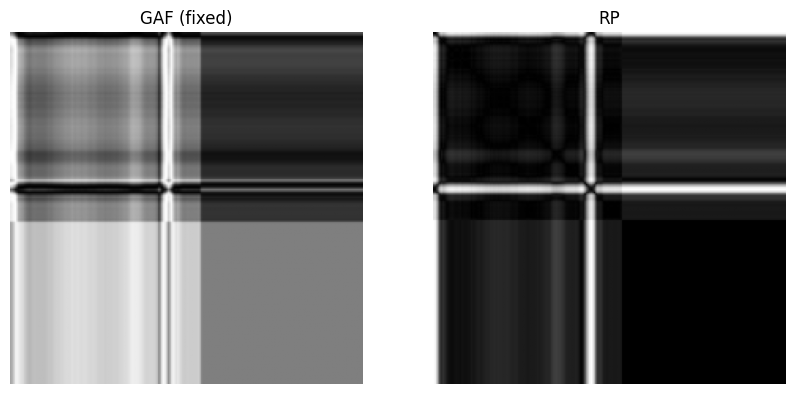

In [ ]:
# Visual check (sampel train pertama)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

for ax, (title, path) in zip(axes, [("GAF (fixed)", GAF_H5), ("RP", RP_H5)]):
    with h5py.File(path, "r") as f:
        image = f["x_train"][0]
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")

plt.show()


# 4. HDF5 Dataset

Satu definisi. File dibuka secara *lazy* (saat sampel pertama dibaca), sehingga aman untuk HDF5 dan DataLoader.

Diperluas di tahap lanjutan: `h5_path` boleh berupa tuple path (dipakai MIF untuk menumpuk GAF, RP, MTF sebagai 3 channel). Untuk satu path, keluaran identik dengan versi sebelumnya.

In [ ]:
class Dataset_Hdf5(Dataset):

    def __init__(self, h5_path, split="train"):
        # h5_path: satu path (gambar 1 channel) atau tuple/list path (MIF: satu channel per file,
        # urutan channel = urutan path). Perilaku untuk satu path identik dengan versi sebelumnya.
        if isinstance(h5_path, (str, os.PathLike)):
            h5_path = (h5_path,)
        self.h5_paths = tuple(h5_path)
        self.split = split

        self.files = None

        lengths = set()
        for path in self.h5_paths:
            with h5py.File(path, "r") as f:
                lengths.add(len(f[f"x_{self.split}"]))
        if len(lengths) != 1:
            raise ValueError(f"Jumlah sampel antar file HDF5 berbeda: {sorted(lengths)}")
        self.length = lengths.pop()

    def _init_files(self):
        if self.files is None:
            self.files = [h5py.File(path, "r") for path in self.h5_paths]

    def __len__(self):
        return self.length

    def __getitem__(self, index):

        self._init_files()

        # C x 224 x 224  (C = 1 untuk satu file)
        image = np.stack(
            [np.asarray(f[f"x_{self.split}"][index], dtype=np.float32) for f in self.files]
        )
        label = self.files[0][f"y_{self.split}"][index]

        image = torch.from_numpy(image)

        label = torch.tensor(label, dtype=torch.long)

        return image, label

    def __del__(self):
        for f in getattr(self, "files", None) or []:
            f.close()


# 5. DataLoader

In [ ]:
def make_loaders(h5_path):
    train_dataset = Dataset_Hdf5(h5_path, split="train")
    test_dataset = Dataset_Hdf5(h5_path, split="test")

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=True,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True,
    )
    return train_loader, test_loader


gaf_train_loader, gaf_test_loader = make_loaders(GAF_H5)
rp_train_loader, rp_test_loader = make_loaders(RP_H5)

print("GAF train/test:", len(gaf_train_loader.dataset), "/", len(gaf_test_loader.dataset))
print("RP  train/test:", len(rp_train_loader.dataset), "/", len(rp_test_loader.dataset))

# Tes 1 batch
for name, loader in [("GAF", gaf_train_loader), ("RP", rp_train_loader)]:
    images, labels = next(iter(loader))
    print(
        f"{name}: images {tuple(images.shape)} {images.dtype} | "
        f"labels {tuple(labels.shape)} {labels.dtype} | "
        f"finite={bool(torch.isfinite(images).all())}"
    )


GAF train/test: 152471 / 21892
RP  train/test: 152471 / 21892
GAF: images (64, 1, 224, 224) torch.float32 | labels (64,) torch.int64 | finite=True
RP: images (64, 1, 224, 224) torch.float32 | labels (64,) torch.int64 | finite=True


# 6. Model

Satu `build_baseline()` untuk GAF dan RP. Pola pemakaian: `net, criterion, optimizer = build_baseline()`.

Catatan: `net.avgpool` tidak punya parameter, jadi grup optimizer ke-3 kosong (tidak berpengaruh). Grup dipertahankan sesuai baseline.

In [ ]:
def build_baseline():

    # ResNet18 pretrained ImageNet
    net = resnet18(
        weights=ResNet18_Weights.IMAGENET1K_V1
    )

    # Freeze semua parameter
    for param in net.parameters():
        param.requires_grad = False

    # Unfreeze layer3
    for param in net.layer3.parameters():
        param.requires_grad = True

    # Unfreeze layer4
    for param in net.layer4.parameters():
        param.requires_grad = True

    # FC sesuai repository
    net.fc = nn.Sequential(
        nn.Linear(512, 256, bias=False),
        nn.ReLU(),
        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Linear(128, 5),
    )

    net = net.to(DEVICE)

    # Class weights
    class_weights = torch.tensor(
        [1, 2, 1, 2, 1],
        dtype=torch.float32,
        device=DEVICE,
    )

    criterion = nn.CrossEntropyLoss(weight=class_weights)

    # Optimizer
    optimizer = optim.Adam(
        [
            {"params": net.layer3.parameters(), "lr": 1e-4},
            {"params": net.layer4.parameters(), "lr": 1e-4},
            {"params": net.avgpool.parameters(), "lr": 1e-4},
            {"params": net.fc[0].parameters(), "lr": 1e-4},
            {"params": net.fc[2].parameters(), "lr": 1e-3},
            {"params": net.fc[4].parameters(), "lr": 2e-3},
        ],
        betas=(0.5, 0.999),
    )

    return net, criterion, optimizer


In [ ]:
# Cek konfigurasi (tidak dipakai untuk training)
_net, _criterion, _optimizer = build_baseline()

group_names = ["layer3", "layer4", "avgpool", "fc[0]", "fc[2]", "fc[4]"]
for name, group in zip(group_names, _optimizer.param_groups):
    n_params = sum(p.numel() for p in group["params"])
    print(f"{name:8s} params={n_params:>10,d}  lr={group['lr']}")

print("betas      :", _optimizer.defaults["betas"])
print("weights    :", _criterion.weight.tolist())
print("trainable  :", sum(p.numel() for p in _net.parameters() if p.requires_grad))

del _net, _criterion, _optimizer
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 193MB/s]


layer3   params= 2,099,712  lr=0.0001
layer4   params= 8,393,728  lr=0.0001
avgpool  params=         0  lr=0.0001
fc[0]    params=   131,072  lr=0.0001
fc[2]    params=    32,896  lr=0.001
fc[4]    params=       645  lr=0.002
betas      : (0.5, 0.999)
weights    : [1.0, 2.0, 1.0, 2.0, 1.0]
trainable  : 10658053


# 7. Training Function

Satu `train()`. Logika, metric, dan checkpoint sama dengan baseline. Dua tambahan perilaku (tidak mengubah hasil numerik):

1. **Guard NaN/Inf**: jika loss tidak finite, `FloatingPointError` dengan diagnosis dan training berhenti.
2. **History per epoch** ditulis ke `outputs/results/history_<ckpt_tag>.csv` agar tidak hilang jika runtime putus.

Checkpoint: `checkpoints/res_net_<ckpt_tag>_test_recall_best.chk` dan `..._test_f1_best.chk`.

In [ ]:
def _raise_nonfinite(stage, epoch, batch_idx, loss_value, inputs, outputs, net, optimizer):
    """Hentikan training dan tampilkan diagnosis saat loss NaN/Inf."""
    bad_params = [n for n, p in net.named_parameters() if not torch.isfinite(p).all()]
    lrs = [g["lr"] for g in optimizer.param_groups]
    n_bad_inputs = int((~torch.isfinite(inputs).flatten(1).all(dim=1)).sum())

    raise FloatingPointError(
        f"\n=== LOSS NON-FINITE ({stage}) ===\n"
        f"epoch / batch        : {epoch} / {batch_idx}\n"
        f"loss                 : {loss_value}\n"
        f"input non-finite     : {n_bad_inputs}/{inputs.shape[0]} sampel dalam batch\n"
        f"output finite        : {bool(torch.isfinite(outputs).all())}\n"
        f"parameter non-finite : {len(bad_params)} {bad_params[:5]}\n"
        f"lr per param group   : {lrs}\n"
        "Kemungkinan penyebab:\n"
        "  1. HDF5 mengandung NaN/Inf          -> jalankan ulang Section 3 (Artifact Validation).\n"
        "  2. GAF_H5 menunjuk file yang salah  -> harus ..._3_fixed.hdf5 (Section 2).\n"
        "  3. Input finite tetapi parameter non-finite -> training diverge (cek lr).\n"
        "Full training JANGAN dijalankan sebelum smoke test lulus."
    )


def train(
    net,
    train_loader,
    criterion,
    optimizer,
    test_loader,
    num_epochs=25,
    ckpt_tag="model",
):

    scheduler = optim.lr_scheduler.ExponentialLR(
        optimizer,
        gamma=0.95,
    )

    history = []

    os.makedirs(CKPT_DIR, exist_ok=True)
    os.makedirs(RESULTS_DIR, exist_ok=True)
    history_path = os.path.join(RESULTS_DIR, f"history_{ckpt_tag}.csv")

    def save_ckpt(kind, epoch, recall, f1):
        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": net.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "recall": recall,
                "f1": f1,
            },
            os.path.join(CKPT_DIR, f"res_net_{ckpt_tag}_test_{kind}_best.chk"),
        )

    best_recall = -1.0
    best_f1 = -1.0

    for epoch in range(num_epochs):

        # ---------------- TRAIN ----------------
        net.train()

        running_loss = 0.0
        train_total = 0
        train_correct = 0

        for batch_idx, (inputs, labels) in enumerate(train_loader):

            inputs = inputs.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if inputs.shape[1] == 1:
                inputs = inputs.expand(-1, 3, -1, -1)

            optimizer.zero_grad()

            outputs = net(inputs)

            loss = criterion(outputs, labels)

            loss_value = loss.item()
            if not math.isfinite(loss_value):
                _raise_nonfinite(
                    "train", epoch + 1, batch_idx, loss_value, inputs, outputs, net, optimizer
                )

            loss.backward()

            optimizer.step()

            running_loss += loss_value * labels.size(0)

            train_total += labels.size(0)

            train_correct += (outputs.argmax(1) == labels).sum().item()

        train_loss = running_loss / train_total

        train_acc = train_correct / train_total

        # ---------------- TEST ----------------
        net.eval()

        test_loss = 0.0
        test_total = 0

        all_labels = []
        all_predictions = []

        with torch.no_grad():

            for batch_idx, (inputs, labels) in enumerate(test_loader):

                inputs = inputs.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)

                if inputs.shape[1] == 1:
                    inputs = inputs.expand(-1, 3, -1, -1)

                outputs = net(inputs)

                loss = criterion(outputs, labels)

                loss_value = loss.item()
                if not math.isfinite(loss_value):
                    _raise_nonfinite(
                        "test", epoch + 1, batch_idx, loss_value, inputs, outputs, net, optimizer
                    )

                test_loss += loss_value * labels.size(0)

                test_total += labels.size(0)

                predictions = outputs.argmax(1)

                all_labels.extend(labels.cpu().numpy())

                all_predictions.extend(predictions.cpu().numpy())

        test_loss /= test_total

        accuracy = accuracy_score(all_labels, all_predictions)

        precision = precision_score(
            all_labels, all_predictions, average="macro", zero_division=0
        )

        recall = recall_score(
            all_labels, all_predictions, average="macro", zero_division=0
        )

        f1 = f1_score(
            all_labels, all_predictions, average="macro", zero_division=0
        )

        scheduler.step()

        history.append(
            {
                "epoch": epoch + 1,
                "train_loss": train_loss,
                "train_accuracy": train_acc,
                "test_loss": test_loss,
                "test_accuracy": accuracy,
                "test_precision": precision,
                "test_recall": recall,
                "test_f1": f1,
            }
        )

        # ---------------- CHECKPOINT ----------------
        if recall > best_recall:
            best_recall = recall
            save_ckpt("recall", epoch + 1, recall, f1)

        if f1 > best_f1:
            best_f1 = f1
            save_ckpt("f1", epoch + 1, recall, f1)

        pd.DataFrame(history).to_csv(history_path, index=False)

        print(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {accuracy:.4f} | "
            f"Macro Precision: {precision:.4f} | "
            f"Macro Recall: {recall:.4f} | "
            f"Macro F1: {f1:.4f}"
        )

    return history


# 8. GAF Smoke Test

2 epoch, API identik dengan full training. Jika loss NaN/Inf, `train()` berhenti dengan diagnosis.
**Periksa tabel hasil sebelum menjalankan Section 9.**

Terkunci `RUN_GAF_SMOKE = False` karena sudah selesai; output run asli di bawah dipertahankan.

In [ ]:
RUN_GAF_SMOKE = False  # smoke test sudah selesai dijalankan; True hanya jika ingin mengulang

if RUN_GAF_SMOKE:
    set_seed(SEED)
    net_gaf, criterion_gaf, optimizer_gaf = build_baseline()

    hist_gaf_test = train(
        net_gaf,
        gaf_train_loader,
        criterion_gaf,
        optimizer_gaf,
        gaf_test_loader,
        num_epochs=2,
        ckpt_tag="gaf_test",
    )

    display(pd.DataFrame(hist_gaf_test).round(4))
else:
    print("DILEWATI: smoke test GAF sudah selesai (lihat output di bawah). Ubah RUN_GAF_SMOKE = True untuk mengulang.")


DILEWATI: smoke test GAF sudah selesai (lihat output di bawah). Ubah RUN_GAF_SMOKE = True untuk mengulang.


# 9. GAF Full Training

25 epoch. **Terkunci** (`RUN_GAF_FULL = False`) agar Run All berhenti di smoke test. Periksa Section 8, lalu ubah flag ke `True` dan jalankan cell ini.

In [ ]:
RUN_GAF_FULL = False  # SUDAH SELESAI (25 epoch). Jangan ubah ke True kecuali ingin melatih ulang.

if RUN_GAF_FULL:
    set_seed(SEED)
    net_gaf, criterion_gaf, optimizer_gaf = build_baseline()

    hist_gaf = train(
        net_gaf,
        gaf_train_loader,
        criterion_gaf,
        optimizer_gaf,
        gaf_test_loader,
        num_epochs=25,
        ckpt_tag="gaf",
    )
else:
    print("DILEWATI: ubah RUN_GAF_FULL = True, lalu jalankan ulang cell ini.")


Epoch 1/25 | Train Loss: 0.0860 | Train Acc: 0.9700 | Test Loss: 0.0732 | Test Acc: 0.9808 | Macro Precision: 0.8753 | Macro Recall: 0.9295 | Macro F1: 0.8974
Epoch 2/25 | Train Loss: 0.0268 | Train Acc: 0.9906 | Test Loss: 0.0652 | Test Acc: 0.9835 | Macro Precision: 0.9071 | Macro Recall: 0.9250 | Macro F1: 0.9155
Epoch 3/25 | Train Loss: 0.0172 | Train Acc: 0.9943 | Test Loss: 0.0745 | Test Acc: 0.9857 | Macro Precision: 0.9271 | Macro Recall: 0.9210 | Macro F1: 0.9240
Epoch 4/25 | Train Loss: 0.0141 | Train Acc: 0.9956 | Test Loss: 0.0779 | Test Acc: 0.9857 | Macro Precision: 0.9130 | Macro Recall: 0.9295 | Macro F1: 0.9202
Epoch 5/25 | Train Loss: 0.0105 | Train Acc: 0.9965 | Test Loss: 0.0921 | Test Acc: 0.9844 | Macro Precision: 0.9279 | Macro Recall: 0.9027 | Macro F1: 0.9147
Epoch 6/25 | Train Loss: 0.0090 | Train Acc: 0.9973 | Test Loss: 0.0759 | Test Acc: 0.9853 | Macro Precision: 0.9144 | Macro Recall: 0.9197 | Macro F1: 0.9170
Epoch 7/25 | Train Loss: 0.0070 | Train Acc: 0

# 10. RP Smoke Test

2 epoch, API identik dengan full training. **Periksa hasil sebelum menjalankan Section 11.**

Terkunci `RUN_RP_SMOKE = False` karena sudah selesai; output run asli di bawah dipertahankan.

In [ ]:
RUN_RP_SMOKE = False  # smoke test sudah selesai dijalankan; True hanya jika ingin mengulang

if RUN_RP_SMOKE:
    set_seed(SEED)
    net_rp, criterion_rp, optimizer_rp = build_baseline()

    hist_rp_test = train(
        net_rp,
        rp_train_loader,
        criterion_rp,
        optimizer_rp,
        rp_test_loader,
        num_epochs=2,
        ckpt_tag="rp_test",
    )

    display(pd.DataFrame(hist_rp_test).round(4))
else:
    print("DILEWATI: smoke test RP sudah selesai (lihat output di bawah). Ubah RUN_RP_SMOKE = True untuk mengulang.")


Epoch 1/2 | Train Loss: 0.0793 | Train Acc: 0.9722 | Test Loss: 0.0667 | Test Acc: 0.9833 | Macro Precision: 0.8917 | Macro Recall: 0.9316 | Macro F1: 0.9084
Epoch 2/2 | Train Loss: 0.0257 | Train Acc: 0.9911 | Test Loss: 0.0685 | Test Acc: 0.9813 | Macro Precision: 0.8914 | Macro Recall: 0.9352 | Macro F1: 0.9109


,epoch,train_loss,train_accuracy,test_loss,test_accuracy,test_precision,test_recall,test_f1
0,1,0.0793,0.9722,0.0667,0.9833,0.8917,0.9316,0.9084
1,2,0.0257,0.9911,0.0685,0.9813,0.8914,0.9352,0.9109


# 11. RP Full Training

25 epoch. **Terkunci** (`RUN_RP_FULL = False`) agar Run All berhenti di smoke test. Periksa Section 10, lalu ubah flag ke `True` dan jalankan cell ini.

In [ ]:
RUN_RP_FULL = False  # SUDAH SELESAI (25 epoch). Jangan ubah ke True kecuali ingin melatih ulang.

if RUN_RP_FULL:
    set_seed(SEED)
    net_rp, criterion_rp, optimizer_rp = build_baseline()

    hist_rp = train(
        net_rp,
        rp_train_loader,
        criterion_rp,
        optimizer_rp,
        rp_test_loader,
        num_epochs=25,
        ckpt_tag="rp",
    )
else:
    print("DILEWATI: ubah RUN_RP_FULL = True, lalu jalankan ulang cell ini.")


Epoch 1/25 | Train Loss: 0.0793 | Train Acc: 0.9722 | Test Loss: 0.0667 | Test Acc: 0.9833 | Macro Precision: 0.8917 | Macro Recall: 0.9316 | Macro F1: 0.9084
Epoch 2/25 | Train Loss: 0.0257 | Train Acc: 0.9911 | Test Loss: 0.0685 | Test Acc: 0.9813 | Macro Precision: 0.8914 | Macro Recall: 0.9352 | Macro F1: 0.9109
Epoch 3/25 | Train Loss: 0.0188 | Train Acc: 0.9939 | Test Loss: 0.0697 | Test Acc: 0.9830 | Macro Precision: 0.9039 | Macro Recall: 0.9312 | Macro F1: 0.9166
Epoch 4/25 | Train Loss: 0.0133 | Train Acc: 0.9954 | Test Loss: 0.0755 | Test Acc: 0.9857 | Macro Precision: 0.9196 | Macro Recall: 0.9290 | Macro F1: 0.9242
Epoch 5/25 | Train Loss: 0.0108 | Train Acc: 0.9966 | Test Loss: 0.1004 | Test Acc: 0.9868 | Macro Precision: 0.9434 | Macro Recall: 0.9120 | Macro F1: 0.9271
Epoch 6/25 | Train Loss: 0.0086 | Train Acc: 0.9975 | Test Loss: 0.0658 | Test Acc: 0.9877 | Macro Precision: 0.9225 | Macro Recall: 0.9310 | Macro F1: 0.9259
Epoch 7/25 | Train Loss: 0.0061 | Train Acc: 0

# 12. Results / Save Metrics

Dibaca dari `outputs/results/history_<tag>.csv` (ditulis `train()` setiap epoch), sehingga tetap bekerja setelah runtime di-restart.
Ringkasan disimpan ke `outputs/results/summary_metrics.csv`.

Catatan metodologi: seperti baseline, checkpoint "best" dipilih berdasarkan metrik **test set** (tidak ada validation set terpisah).

In [ ]:
METRICS = [
    "train_loss", "train_accuracy", "test_loss", "test_accuracy",
    "test_precision", "test_recall", "test_f1",
]

rows = []
for tag in ["gaf_test", "gaf", "rp_test", "rp"]:
    path = os.path.join(RESULTS_DIR, f"history_{tag}.csv")

    if not os.path.exists(path):
        print(f"(belum ada) {tag}")
        continue

    h = pd.read_csv(path)
    last = h.iloc[-1]
    best_f1 = h.loc[h["test_f1"].idxmax()]
    best_recall = h.loc[h["test_recall"].idxmax()]

    row = {"run": tag, "epochs": len(h)}
    row.update({f"final_{m}": last[m] for m in METRICS})
    row.update(
        {
            "best_f1_epoch": int(best_f1["epoch"]),
            "best_f1": best_f1["test_f1"],
            "best_recall_epoch": int(best_recall["epoch"]),
            "best_recall": best_recall["test_recall"],
        }
    )
    rows.append(row)

if rows:
    summary = pd.DataFrame(rows)
    summary_path = os.path.join(RESULTS_DIR, "summary_metrics.csv")
    summary.to_csv(summary_path, index=False)
    print("Saved:", summary_path)
    display(summary.round(4))
else:
    print("Belum ada history. Jalankan smoke test / full training terlebih dahulu.")


Saved: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/outputs/results/summary_metrics.csv


,run,epochs,final_train_loss,final_train_accuracy,final_test_loss,final_test_accuracy,final_test_precision,final_test_recall,final_test_f1,best_f1_epoch,best_f1,best_recall_epoch,best_recall
0,gaf_test,2,0.0268,0.9906,0.0652,0.9835,0.9071,0.9250,0.9155,2,0.9155,1,0.9295
1,gaf,25,0.0006,0.9998,0.1615,0.9886,0.9419,0.9185,0.9299,21,0.9353,8,0.9295
2,rp_test,2,0.0257,0.9911,0.0685,0.9813,0.8914,0.9352,0.9109,2,0.9109,2,0.9352
3,rp,25,0.0009,0.9998,0.1355,0.9883,0.9417,0.9265,0.9337,24,0.9364,2,0.9352


# 13. MTF Preparation

Tahap lanjutan replikasi. **Run policy** (semua default `False`; tidak ada proses mahal otomatis):

| Flag | Cell | Fungsi |
|---|---|---|
| `RUN_MTF` | §13 | Membuat `hb_data_mit_bih_balanced_mtf.hdf5` (~35 GB) bila belum ada |
| `RUN_MTF_SMOKE` / `RUN_MTF_FULL` | §14 | Latih CNN MTF (2 / 25 epoch), tag `mtf_test` / `mtf` |
| `RUN_MIF_SMOKE` / `RUN_MIF_FULL` | §16 | Latih CNN MIF 3-channel (2 / 25 epoch), tag `mif_test` / `mif` |
| `RUN_MFF` | §17, §19 | Ekstraksi fitur, SVM, dan FC head fusion |

Aturan resume: artifact **valid** → LOAD; tidak ada → buat hanya jika flag `True`; selain itu tercatat **NOT RUN**. GAF/RP tidak pernah dilatih ulang.

**MTF mengikuti repositori** (`heartbeat_data_generator-MITBIH.ipynb`, `get_mtf`): 10 bin lebar-sama pada [0, 1], matriks transisi orde-1 dinormalisasi per baris, dipetakan ke 187×187, skala `r/5 − 1` (rentang **[−1, −0.8]**), resize bilinear ke 224×224, float32. Paper memakai bin kuantil (Eq. 5); perbedaan dicatat di Section 21.

In [ ]:
# ---- Import, konstanta, dan helper bersama Section 13-22 (didefinisikan SEKALI di sini) ----
import json

import joblib
import torch.nn.functional as F
from PIL import Image
from sklearn.metrics import confusion_matrix
from sklearn.svm import LinearSVC
from torch.utils.data import TensorDataset

CLASS_NAMES = ["N", "S", "V", "F", "Q"]

NUM_EPOCHS_SMOKE = 2
NUM_EPOCHS_FULL = 25       # sama dengan GAF/RP (Section 9 dan 11)
NUM_EPOCHS_MFF_HEAD = 30   # sesuai repo: heartbeat_fusion_MITBIH.ipynb -> train(net, ..., 30)

# Jumlah epoch yang diharapkan di history_<tag>.csv untuk run penuh
HISTORY_EPOCHS = {
    "gaf": NUM_EPOCHS_FULL, "rp": NUM_EPOCHS_FULL, "mtf": NUM_EPOCHS_FULL,
    "mif": NUM_EPOCHS_FULL, "mff_concat": NUM_EPOCHS_MFF_HEAD,
}


def ckpt_path(tag, kind):
    """Nama checkpoint persis seperti yang ditulis train(): res_net_<tag>_test_<kind>_best.chk"""
    return os.path.join(CKPT_DIR, f"res_net_{tag}_test_{kind}_best.chk")


def history_path(tag):
    return os.path.join(RESULTS_DIR, f"history_{tag}.csv")


def training_artifacts_valid(tag, num_epochs):
    """True jika history lengkap (num_epochs baris, kolom benar, semua finite) dan kedua checkpoint ada."""
    paths = [history_path(tag), ckpt_path(tag, "recall"), ckpt_path(tag, "f1")]
    if not all(os.path.exists(p) for p in paths):
        return False
    h = pd.read_csv(history_path(tag))
    return (
        list(h.columns) == ["epoch"] + METRICS
        and len(h) == num_epochs
        and bool(np.isfinite(h.to_numpy()).all())
    )


def load_history(tag):
    return pd.read_csv(history_path(tag))


def read_ckpt_meta(tag, kind):
    ckpt = torch.load(ckpt_path(tag, kind), map_location="cpu", weights_only=False)
    return {"epoch": int(ckpt["epoch"]), "recall": float(ckpt["recall"]), "f1": float(ckpt["f1"])}


def load_checkpoint(net, tag, kind):
    # weights_only=False: checkpoint ditulis sendiri oleh train() dan berisi scalar numpy
    ckpt = torch.load(ckpt_path(tag, kind), map_location=DEVICE, weights_only=False)
    net.load_state_dict(ckpt["model_state_dict"])
    return ckpt


def compute_metrics(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


def predict(net, loader):
    net.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(DEVICE, non_blocking=True)
            if inputs.shape[1] == 1:
                inputs = inputs.expand(-1, 3, -1, -1)
            y_pred.append(net(inputs).argmax(1).cpu().numpy())
            y_true.append(labels.numpy())
    return np.concatenate(y_true), np.concatenate(y_pred)


def atomic_savez(path, **arrays):
    """Tulis ke file sementara lalu rename, sehingga run terputus tidak meninggalkan file setengah jadi."""
    tmp = path[:-4] + ".tmp.npz"
    np.savez(tmp, **arrays)
    os.replace(tmp, path)


def predictions_valid(path, ckpt_epoch):
    if not os.path.exists(path):
        return False
    try:
        d = np.load(path)
        return (
            d["y_true"].shape == (N_TEST,)
            and d["y_pred"].shape == (N_TEST,)
            and np.array_equal(d["y_true"], y_test_ref)
            and 0 <= int(d["y_pred"].min()) and int(d["y_pred"].max()) <= 4
            and int(d["ckpt_epoch"]) == ckpt_epoch
        )
    except Exception:
        return False


def evaluate_model(name, tag, kind, make_net, make_loader):
    """Metrik test set dari checkpoint <tag>/<kind>. Prediksi valid -> LOAD; selain itu inferensi (TANPA training).
    Mengembalikan None bila checkpoint belum ada (NOT RUN)."""
    if not os.path.exists(ckpt_path(tag, kind)):
        return None

    meta = read_ckpt_meta(tag, kind)
    pred_path = os.path.join(RESULTS_DIR, f"predictions_{name}.npz")

    if predictions_valid(pred_path, meta["epoch"]):
        d = np.load(pred_path)
        y_true, y_pred = d["y_true"], d["y_pred"]
        print(f"LOAD  predictions_{name}.npz")
    else:
        loader = make_loader()
        if loader is None:
            raise RuntimeError(f"{name}: checkpoint ada tetapi data HDF5 belum tersedia")
        net = make_net()
        load_checkpoint(net, tag, kind)
        y_true, y_pred = predict(net, loader)

        # integritas: angka rekomputasi harus sama dengan yang tercatat saat training
        key = "f1" if kind == "f1" else "recall"
        got = compute_metrics(y_true, y_pred)[key]
        if abs(got - meta[key]) > 1e-3:
            raise RuntimeError(
                f"{name}: macro-{key} rekomputasi {got:.4f} != tercatat di checkpoint {meta[key]:.4f}. "
                "Checkpoint, loader, atau data tidak cocok."
            )
        atomic_savez(pred_path, y_true=y_true, y_pred=y_pred, ckpt_epoch=np.array(meta["epoch"]))
        print(f"SAVE  predictions_{name}.npz")

    return {**compute_metrics(y_true, y_pred), "epoch": meta["epoch"], "y_true": y_true, "y_pred": y_pred}


In [ ]:
MTF_H5 = os.path.join(HDF5_DIR, "hb_data_mit_bih_balanced_mtf.hdf5")
MTF_BINS = 10


def get_quantiles(min_value=0, max_val=1, k=MTF_BINS):
    # persis repo (heartbeat_data_generator-MITBIH.ipynb): batas atas 10 bin lebar-sama pada [0, 1]
    c = (max_val - min_value) / k
    b = min_value + c
    d = []
    for i in range(1, k):
        d.append(b)
        b += c
    d.append(max_val)
    return d


MTF_QUANTILES = np.array(get_quantiles())


def mtf_batch(X):
    """MTF (B, 187, 187), skala r/5 - 1. Setara numerik dengan get_mtf() di repo, hanya divektorisasi."""
    X = np.asarray(X, dtype=np.float64)

    # bin = indeks pertama i dengan x <= quantiles[i]; x di atas batas terakhir -> 0 (seperti repo)
    q = np.searchsorted(MTF_QUANTILES, X, side="left")
    q[q == MTF_BINS] = 0

    out = np.empty((len(X), X.shape[1], X.shape[1]), dtype=np.float64)
    for b in range(len(X)):
        counts = np.bincount(
            q[b, :-1] * MTF_BINS + q[b, 1:], minlength=MTF_BINS ** 2
        ).reshape(MTF_BINS, MTF_BINS).astype(np.float64)

        with np.errstate(divide="ignore", invalid="ignore"):
            y = counts / counts.sum(axis=1, keepdims=True)
        y[np.isnan(y)] = 0

        out[b] = y[q[b][:, None], q[b][None, :]]

    return out / 5.0 - 1


def mtf_resized(X):
    """(B, 187) -> (B, 224, 224) float32, resize bilinear (sama dengan GAF/RP)."""
    mtf = mtf_batch(X)
    out = np.empty((len(mtf), 224, 224), dtype=np.float32)
    for i, m in enumerate(mtf):
        image = Image.fromarray(m.astype(np.float32))
        image = image.resize((224, 224), Image.Resampling.BILINEAR)
        out[i] = np.asarray(image, dtype=np.float32)
    return out


def build_mtf_hdf5(out_path):
    X = {
        "train": np.load(FEATURE_PATHS["X_train_smote.npy"], mmap_mode="r"),
        "test": np.load(FEATURE_PATHS["X_test.npy"], mmap_mode="r"),
    }
    y = {
        "train": np.asarray(y_train_ref, dtype=np.int32),
        "test": np.asarray(y_test_ref, dtype=np.int32),
    }

    tmp_path = out_path + ".tmp"
    if os.path.exists(tmp_path):
        os.remove(tmp_path)  # sisa run terputus (bukan artifact valid)

    batch_size = 256

    with h5py.File(tmp_path, "w") as f:
        for split in ("train", "test"):
            n = len(X[split])

            x_ds = f.create_dataset(
                f"x_{split}", shape=(n, 224, 224), dtype=np.float32, chunks=(1, 224, 224)
            )
            y_ds = f.create_dataset(f"y_{split}", shape=(n,), dtype=np.int32)

            for start in range(0, n, batch_size):
                end = min(start + batch_size, n)

                batch = mtf_resized(X[split][start:end])

                if not np.isfinite(batch).all():
                    raise ValueError(f"MTF {split.upper()} {start}:{end} mengandung NaN/Inf")
                if batch.min() < -1.001 or batch.max() > -0.799:
                    raise ValueError(
                        f"MTF {split.upper()} {start}:{end} di luar [-1, -0.8]: "
                        f"min={batch.min()}, max={batch.max()}"
                    )

                x_ds[start:end] = batch
                y_ds[start:end] = y[split][start:end]

                if (start // batch_size) % 20 == 0:
                    print(f"{split.upper()}: {end}/{n}")

    os.replace(tmp_path, out_path)
    print("\nMTF HDF5 selesai:", out_path)


In [ ]:
RUN_MTF = True  # True = BUAT file MTF (~35 GB, lama). Jika file sudah ada, TIDAK dibuat ulang.

if os.path.exists(MTF_H5):
    print("SKIP: MTF sudah ada ->", MTF_H5, "(divalidasi di Section 14)")
elif RUN_MTF:
    build_mtf_hdf5(MTF_H5)
else:
    print("NOT GENERATED: file MTF belum ada. Set RUN_MTF = True untuk membuatnya. Section 14-16 yang bergantung MTF akan di-SKIP.")


TRAIN: 256/152471
TRAIN: 5376/152471
TRAIN: 10496/152471
TRAIN: 15616/152471
TRAIN: 20736/152471
TRAIN: 25856/152471
TRAIN: 30976/152471
TRAIN: 36096/152471
TRAIN: 41216/152471
TRAIN: 46336/152471
TRAIN: 51456/152471
TRAIN: 56576/152471
TRAIN: 61696/152471
TRAIN: 66816/152471
TRAIN: 71936/152471
TRAIN: 77056/152471
TRAIN: 82176/152471
TRAIN: 87296/152471
TRAIN: 92416/152471
TRAIN: 97536/152471
TRAIN: 102656/152471
TRAIN: 107776/152471
TRAIN: 112896/152471
TRAIN: 118016/152471
TRAIN: 123136/152471
TRAIN: 128256/152471
TRAIN: 133376/152471
TRAIN: 138496/152471
TRAIN: 143616/152471
TRAIN: 148736/152471
TEST: 256/21892
TEST: 5376/21892
TEST: 10496/21892
TEST: 15616/21892
TEST: 20736/21892

MTF HDF5 selesai: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/hdf5/hb_data_mit_bih_balanced_mtf.hdf5


# 14. MTF Validation

Memeriksa file ada, shape, dtype, NaN, Inf, range, label (terhadap `features/*.npy`), dan **konten**: beberapa sampel (awal, tengah, ujung SMOTE) dihitung ulang dari `features/X_*.npy` lalu dibandingkan dengan isi HDF5.
Rentang MTF yang benar: **[−1, −0.8]** (karena skala `r/5 − 1` pada probabilitas 0..1). File yang sudah ada tidak pernah dihapus; file tidak valid menghentikan Run All.

In [ ]:
MTF_READY = False

if not os.path.exists(MTF_H5):
    print("NOT RUN: file MTF belum ada. Section 14 (training MTF), 15, 16, 17 yang memakai MTF di-SKIP.")
else:
    mtf_problems = validate_hdf5(MTF_H5, "MTF", y_train_ref, y_test_ref)

    with h5py.File(MTF_H5, "r") as f:
        # range khusus MTF + bukan konstan
        for key in ("x_train", "x_test"):
            n_read, n_nan, n_inf, lo, hi = _scan_images(f[key])
            print(f"  MTF {key}: min={lo:.4f} max={hi:.4f}")
            if lo < -1.001 or hi > -0.799:
                mtf_problems.append(f"MTF/{key}: range [{lo:.4f}, {hi:.4f}] di luar [-1, -0.8]")
            if hi - lo < 1e-6:
                mtf_problems.append(f"MTF/{key}: konstan")

        # konten: hitung ulang dari features (awal, tengah, ujung) dan bandingkan
        for split, fname in (("train", "X_train_smote.npy"), ("test", "X_test.npy")):
            X = np.load(FEATURE_PATHS[fname], mmap_mode="r")
            idx = np.linspace(0, len(X) - 1, 8, dtype=int)
            stored = f[f"x_{split}"][idx]
            expected = mtf_resized(X[idx])
            if not np.allclose(stored, expected, atol=1e-6):
                mtf_problems.append(f"MTF/x_{split}: isi tidak cocok dengan hitung ulang dari features (indeks {idx.tolist()})")

    if mtf_problems:
        raise RuntimeError("Validasi MTF GAGAL (file TIDAK dihapus):\n  - " + "\n  - ".join(mtf_problems))

    MTF_READY = True
    print("\nMTF VALID.", "(full scan)" if FULL_SCAN else "(sampling blok merata + ujung array)")



[MTF] hb_data_mit_bih_balanced_mtf.hdf5
  x_train  shape=(152471, 224, 224) dtype=float32 | 1024 sampel: NaN=0 Inf=0 min=-1.0000 max=-0.8000
  y_train  shape=(152471,) dtype=int32
  x_test   shape=(21892, 224, 224) dtype=float32 | 1024 sampel: NaN=0 Inf=0 min=-1.0000 max=-0.8000
  y_test   shape=(21892,) dtype=int32
  label    train={0: 72471, 1: 30000, 2: 20000, 3: 20000, 4: 10000}
  MTF x_train: min=-1.0000 max=-0.8000
  MTF x_test: min=-1.0000 max=-0.8000

MTF VALID. (sampling blok merata + ujung array)


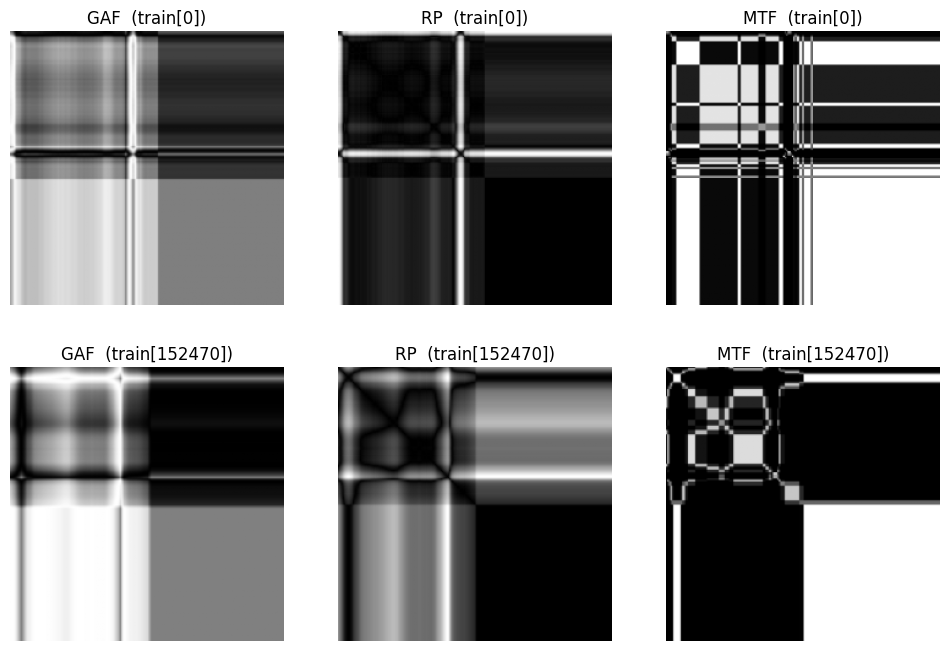

In [ ]:
# Visual check: GAF | RP | MTF untuk sampel train pertama dan sampel terakhir (hasil SMOTE)
if MTF_READY:
    fig, axes = plt.subplots(2, 3, figsize=(12, 8))

    for row, index in enumerate([0, N_TRAIN - 1]):
        for ax, (title, path) in zip(axes[row], [("GAF", GAF_H5), ("RP", RP_H5), ("MTF", MTF_H5)]):
            with h5py.File(path, "r") as f:
                image = f["x_train"][index]
            ax.imshow(image, cmap="gray")
            ax.set_title(f"{title}  (train[{index}])")
            ax.axis("off")

    plt.show()
else:
    print("SKIP: MTF belum tersedia.")


## 14.1 MTF CNN — Smoke Test

ResNet18 yang sama (`build_baseline()`) dan `train()` yang sama dengan GAF/RP. Tag: `mtf_test`.

In [ ]:
RUN_MTF_SMOKE = True  # True = latih 2 epoch. Jika history+checkpoint valid sudah ada, di-LOAD (tidak dilatih ulang).

mtf_train_loader = mtf_test_loader = None
if MTF_READY:
    mtf_train_loader, mtf_test_loader = make_loaders(MTF_H5)

hist_mtf_test = None

if not MTF_READY:
    print("SKIP: MTF belum tersedia.")
elif training_artifacts_valid("mtf_test", NUM_EPOCHS_SMOKE):
    print("LOAD: history_mtf_test.csv (+ checkpoint) sudah valid, tidak dilatih ulang.")
    hist_mtf_test = load_history("mtf_test").to_dict("records")
elif RUN_MTF_SMOKE:
    set_seed(SEED)
    net_mtf, criterion_mtf, optimizer_mtf = build_baseline()

    hist_mtf_test = train(
        net_mtf,
        mtf_train_loader,
        criterion_mtf,
        optimizer_mtf,
        mtf_test_loader,
        num_epochs=NUM_EPOCHS_SMOKE,
        ckpt_tag="mtf_test",
    )
else:
    print("NOT RUN: set RUN_MTF_SMOKE = True untuk smoke test MTF.")

if hist_mtf_test is not None:
    display(pd.DataFrame(hist_mtf_test).round(4))


Epoch 1/2 | Train Loss: 0.1982 | Train Acc: 0.9281 | Test Loss: 0.1649 | Test Acc: 0.9440 | Macro Precision: 0.7449 | Macro Recall: 0.8914 | Macro F1: 0.7864
Epoch 2/2 | Train Loss: 0.0763 | Train Acc: 0.9715 | Test Loss: 0.2005 | Test Acc: 0.9336 | Macro Precision: 0.7259 | Macro Recall: 0.9069 | Macro F1: 0.7743


,epoch,train_loss,train_accuracy,test_loss,test_accuracy,test_precision,test_recall,test_f1
0,1,0.1982,0.9281,0.1649,0.9440,0.7449,0.8914,0.7864
1,2,0.0763,0.9715,0.2005,0.9336,0.7259,0.9069,0.7743


## 14.2 MTF CNN — Full Training

25 epoch, tag `mtf`. **Periksa smoke test (14.1) lebih dulu.**

In [ ]:
RUN_MTF_FULL = True  # True = latih 25 epoch (setelah smoke test diperiksa). Valid sudah ada -> LOAD.

hist_mtf = None

if not MTF_READY:
    print("SKIP: MTF belum tersedia.")
elif training_artifacts_valid("mtf", NUM_EPOCHS_FULL):
    print("LOAD: history_mtf.csv (+ checkpoint) sudah valid, tidak dilatih ulang.")
    hist_mtf = load_history("mtf").to_dict("records")
elif RUN_MTF_FULL:
    set_seed(SEED)
    net_mtf, criterion_mtf, optimizer_mtf = build_baseline()

    hist_mtf = train(
        net_mtf,
        mtf_train_loader,
        criterion_mtf,
        optimizer_mtf,
        mtf_test_loader,
        num_epochs=NUM_EPOCHS_FULL,
        ckpt_tag="mtf",
    )
else:
    print("NOT RUN: set RUN_MTF_FULL = True untuk training penuh MTF.")


Epoch 1/25 | Train Loss: 0.1982 | Train Acc: 0.9281 | Test Loss: 0.1649 | Test Acc: 0.9440 | Macro Precision: 0.7449 | Macro Recall: 0.8914 | Macro F1: 0.7864
Epoch 2/25 | Train Loss: 0.0763 | Train Acc: 0.9715 | Test Loss: 0.2005 | Test Acc: 0.9336 | Macro Precision: 0.7259 | Macro Recall: 0.9069 | Macro F1: 0.7743
Epoch 3/25 | Train Loss: 0.0476 | Train Acc: 0.9826 | Test Loss: 0.1329 | Test Acc: 0.9626 | Macro Precision: 0.8043 | Macro Recall: 0.8868 | Macro F1: 0.8346
Epoch 4/25 | Train Loss: 0.0320 | Train Acc: 0.9883 | Test Loss: 0.1363 | Test Acc: 0.9656 | Macro Precision: 0.8070 | Macro Recall: 0.8972 | Macro F1: 0.8424
Epoch 5/25 | Train Loss: 0.0232 | Train Acc: 0.9918 | Test Loss: 0.1548 | Test Acc: 0.9693 | Macro Precision: 0.8451 | Macro Recall: 0.8865 | Macro F1: 0.8631
Epoch 6/25 | Train Loss: 0.0191 | Train Acc: 0.9935 | Test Loss: 0.1625 | Test Acc: 0.9656 | Macro Precision: 0.8236 | Macro Recall: 0.8854 | Macro F1: 0.8486
Epoch 7/25 | Train Loss: 0.0158 | Train Acc: 0

# 15. MIF — Multimodal Image Fusion

Gambar fusi 3-channel **GAF–RP–MTF** (urutan channel sama dengan repo: 0=GAF, 1=RP, 2=MTF), masuk langsung ke ResNet18 (`conv1` 3-channel, tanpa `expand`).

Repo menyimpan tensor ini sebagai HDF5 `(N, 3, 224, 224)` (~92 GB). Di sini channel **ditumpuk saat dibaca** dari tiga HDF5 yang sudah tervalidasi lewat `Dataset_Hdf5((GAF_H5, RP_H5, MTF_H5))`. Isinya identik, tanpa file baru, sehingga tidak ada artifact fusi yang perlu dibuat.

In [ ]:
MIF_SOURCES = (GAF_H5, RP_H5, MTF_H5)  # urutan channel: GAF, RP, MTF

mif_train_loader = mif_test_loader = None

if not MTF_READY:
    print("SKIP: MIF membutuhkan MTF.")
else:
    mif_train_loader, mif_test_loader = make_loaders(MIF_SOURCES)

    assert len(mif_train_loader.dataset) == N_TRAIN and len(mif_test_loader.dataset) == N_TEST

    # 1 batch: shape + finite
    images, labels = next(iter(mif_train_loader))
    print(f"MIF batch: images {tuple(images.shape)} {images.dtype} | finite={bool(torch.isfinite(images).all())}")
    assert tuple(images.shape) == (BATCH_SIZE, 3, 224, 224)

    # channel = tepat sama dengan modalitas tunggal, label sejajar
    for split, ds_mif, y_ref in (
        ("train", mif_train_loader.dataset, y_train_ref),
        ("test", mif_test_loader.dataset, y_test_ref),
    ):
        for index in (0, len(ds_mif) // 2, len(ds_mif) - 1):
            fused, label = ds_mif[index]
            for ch, path in enumerate(MIF_SOURCES):
                single, single_label = Dataset_Hdf5(path, split=split)[index]
                assert torch.equal(fused[ch:ch + 1], single), f"channel {ch} != modalitas tunggal ({split}[{index}])"
                assert int(single_label) == int(label) == int(y_ref[index])
    print("MIF VALID: channel = GAF/RP/MTF, label sejajar.")


MIF batch: images (64, 3, 224, 224) torch.float32 | finite=True
MIF VALID: channel = GAF/RP/MTF, label sejajar.


# 16. MIF Training / Evaluation

`build_baseline()` + `train()` yang sama. Tag `mif_test` / `mif`. Catatan I/O: setiap sampel membaca 3 file HDF5, sehingga satu epoch kira-kira ~3× lebih lambat dari GAF/RP.

In [ ]:
RUN_MIF_SMOKE = True  # True = latih 2 epoch. Valid sudah ada -> LOAD.

hist_mif_test = None

if mif_train_loader is None:
    print("SKIP: MIF belum tersedia (butuh MTF).")
elif training_artifacts_valid("mif_test", NUM_EPOCHS_SMOKE):
    print("LOAD: history_mif_test.csv (+ checkpoint) sudah valid, tidak dilatih ulang.")
    hist_mif_test = load_history("mif_test").to_dict("records")
elif RUN_MIF_SMOKE:
    set_seed(SEED)
    net_mif, criterion_mif, optimizer_mif = build_baseline()

    hist_mif_test = train(
        net_mif,
        mif_train_loader,
        criterion_mif,
        optimizer_mif,
        mif_test_loader,
        num_epochs=NUM_EPOCHS_SMOKE,
        ckpt_tag="mif_test",
    )
else:
    print("NOT RUN: set RUN_MIF_SMOKE = True untuk smoke test MIF.")

if hist_mif_test is not None:
    display(pd.DataFrame(hist_mif_test).round(4))


Epoch 1/2 | Train Loss: 0.0815 | Train Acc: 0.9717 | Test Loss: 0.0609 | Test Acc: 0.9838 | Macro Precision: 0.8949 | Macro Recall: 0.9336 | Macro F1: 0.9118
Epoch 2/2 | Train Loss: 0.0268 | Train Acc: 0.9909 | Test Loss: 0.0713 | Test Acc: 0.9826 | Macro Precision: 0.9020 | Macro Recall: 0.9230 | Macro F1: 0.9118


,epoch,train_loss,train_accuracy,test_loss,test_accuracy,test_precision,test_recall,test_f1
0,1,0.0815,0.9717,0.0609,0.9838,0.8949,0.9336,0.9118
1,2,0.0268,0.9909,0.0713,0.9826,0.9020,0.9230,0.9118


In [27]:
RUN_MIF_FULL = True  # True = latih 25 epoch (setelah smoke test diperiksa). Valid sudah ada -> LOAD.

hist_mif = None

if mif_train_loader is None:
    print("SKIP: MIF belum tersedia (butuh MTF).")
elif training_artifacts_valid("mif", NUM_EPOCHS_FULL):
    print("LOAD: history_mif.csv (+ checkpoint) sudah valid, tidak dilatih ulang.")
    hist_mif = load_history("mif").to_dict("records")
elif RUN_MIF_FULL:
    set_seed(SEED)
    net_mif, criterion_mif, optimizer_mif = build_baseline()

    hist_mif = train(
        net_mif,
        mif_train_loader,
        criterion_mif,
        optimizer_mif,
        mif_test_loader,
        num_epochs=NUM_EPOCHS_FULL,
        ckpt_tag="mif",
    )
else:
    print("NOT RUN: set RUN_MIF_FULL = True untuk training penuh MIF.")


Epoch 1/25 | Train Loss: 0.0815 | Train Acc: 0.9717 | Test Loss: 0.0609 | Test Acc: 0.9838 | Macro Precision: 0.8949 | Macro Recall: 0.9336 | Macro F1: 0.9118
Epoch 2/25 | Train Loss: 0.0268 | Train Acc: 0.9909 | Test Loss: 0.0713 | Test Acc: 0.9826 | Macro Precision: 0.9020 | Macro Recall: 0.9230 | Macro F1: 0.9118
Epoch 3/25 | Train Loss: 0.0178 | Train Acc: 0.9939 | Test Loss: 0.0616 | Test Acc: 0.9852 | Macro Precision: 0.9147 | Macro Recall: 0.9301 | Macro F1: 0.9218
Epoch 4/25 | Train Loss: 0.0132 | Train Acc: 0.9956 | Test Loss: 0.0792 | Test Acc: 0.9838 | Macro Precision: 0.8862 | Macro Recall: 0.9333 | Macro F1: 0.9065
Epoch 5/25 | Train Loss: 0.0094 | Train Acc: 0.9969 | Test Loss: 0.0872 | Test Acc: 0.9873 | Macro Precision: 0.9316 | Macro Recall: 0.9245 | Macro F1: 0.9280
Epoch 6/25 | Train Loss: 0.0090 | Train Acc: 0.9970 | Test Loss: 0.0880 | Test Acc: 0.9861 | Macro Precision: 0.9172 | Macro Recall: 0.9299 | Macro F1: 0.9233
Epoch 7/25 | Train Loss: 0.0062 | Train Acc: 0

In [28]:
# Evaluasi MIF (checkpoint macro-F1 terbaik). Prediksi valid -> LOAD; tanpa training.
mif_metrics = evaluate_model(
    "mif_f1", "mif", "f1",
    make_net=lambda: build_baseline()[0],
    make_loader=lambda: mif_test_loader,
)

if mif_metrics is None:
    print("NOT RUN: MIF belum dilatih (checkpoint tidak ada).")
else:
    print({k: round(float(v), 4) for k, v in mif_metrics.items() if k in ("accuracy", "precision", "recall", "f1", "epoch")})
    print(confusion_matrix(mif_metrics["y_true"], mif_metrics["y_pred"]))


SAVE  predictions_mif_f1.npz
{'accuracy': 0.9891, 'precision': 0.9493, 'recall': 0.9219, 'f1': 0.9349, 'epoch': 25.0}
[[18065    29    11     9     4]
 [   90   460     4     1     1]
 [   34     1  1398    15     0]
 [   14     1    13   134     0]
 [    9     0     3     0  1596]]


# 17. MFF Feature Extraction

Fitur **512-d** (keluaran `avgpool`, `fc = Identity`) dari ResNet18 yang sudah di-fine-tune, satu per modalitas (GAF, RP, MTF), memakai **checkpoint `recall` terbaik** seperti repo (`res_net_test_recall_best_*.chk`). Checkpoint GAF/RP yang sudah ada **dipakai ulang**, tanpa training ulang.

Berbeda dari repo: model diset `.eval()` dan loader **tidak diacak** (`shuffle=False`) sehingga baris fitur antar modalitas sejajar. Repo men-`zip` loader GAF `shuffle=True` dengan loader RP `shuffle=False` dan tidak memanggil `.eval()` (lihat Section 21).

Fitur disimpan ke `features/mff_features_<tag>_recall.npz` dan dianggap valid hanya bila shape, dtype, finite, label, **dan epoch checkpoint asalnya** cocok.

In [30]:
RUN_MFF = True  # True = ekstraksi fitur (§17), fit SVM dan FC head (§19) bila artifact belum ada.

FUSION_CKPT_KIND = "recall"  # sesuai repo
FEATURE_DIM = 512
FEATURE_SOURCES = {"gaf": GAF_H5, "rp": RP_H5, "mtf": MTF_H5}


def mff_feature_path(tag):
    return os.path.join(FEATURES_DIR, f"mff_features_{tag}_{FUSION_CKPT_KIND}.npz")


def mff_features_valid(tag):
    if not os.path.exists(mff_feature_path(tag)) or not os.path.exists(ckpt_path(tag, FUSION_CKPT_KIND)):
        return False
    try:
        d = np.load(mff_feature_path(tag))
        return (
            d["x_train"].shape == (N_TRAIN, FEATURE_DIM) and d["x_test"].shape == (N_TEST, FEATURE_DIM)
            and d["x_train"].dtype == np.float32 and d["x_test"].dtype == np.float32
            and bool(np.isfinite(d["x_train"]).all()) and bool(np.isfinite(d["x_test"]).all())
            and np.array_equal(d["y_train"], y_train_ref) and np.array_equal(d["y_test"], y_test_ref)
            and int(d["ckpt_epoch"]) == read_ckpt_meta(tag, FUSION_CKPT_KIND)["epoch"]
        )
    except Exception:
        return False


def extract_features(tag, h5_path):
    net, _, _ = build_baseline()
    load_checkpoint(net, tag, FUSION_CKPT_KIND)
    net.fc = nn.Identity()
    net.eval()

    arrays = {"ckpt_epoch": np.array(read_ckpt_meta(tag, FUSION_CKPT_KIND)["epoch"])}

    for split in ("train", "test"):
        loader = DataLoader(
            Dataset_Hdf5(h5_path, split=split),
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=0,
            pin_memory=True,
        )
        feats, labels = [], []
        with torch.no_grad():
            for inputs, y in loader:
                inputs = inputs.to(DEVICE, non_blocking=True)
                if inputs.shape[1] == 1:
                    inputs = inputs.expand(-1, 3, -1, -1)
                feats.append(net(inputs).cpu().numpy())
                labels.append(y.numpy())
        arrays[f"x_{split}"] = np.concatenate(feats).astype(np.float32)
        arrays[f"y_{split}"] = np.concatenate(labels).astype(np.int32)
        print(f"  {tag} {split}: {arrays[f'x_{split}'].shape}")

    atomic_savez(mff_feature_path(tag), **arrays)


mff_features = {}

for tag, h5_path in FEATURE_SOURCES.items():
    if mff_features_valid(tag):
        mff_features[tag] = dict(np.load(mff_feature_path(tag)))
        print(f"LOAD    {tag}: fitur valid (ckpt epoch {int(mff_features[tag]['ckpt_epoch'])})")
    elif not os.path.exists(ckpt_path(tag, FUSION_CKPT_KIND)):
        print(f"NOT RUN {tag}: checkpoint {os.path.basename(ckpt_path(tag, FUSION_CKPT_KIND))} belum ada.")
    elif tag == "mtf" and not MTF_READY:
        print("NOT RUN mtf: HDF5 MTF belum tersedia.")
    elif RUN_MFF:
        print(f"EXTRACT {tag} ...")
        extract_features(tag, h5_path)
        mff_features[tag] = dict(np.load(mff_feature_path(tag)))
        assert mff_features_valid(tag), f"fitur {tag} tidak valid setelah ekstraksi"
    else:
        print(f"NOT RUN {tag}: set RUN_MFF = True untuk ekstraksi fitur.")

MFF_READY = all(tag in mff_features for tag in FEATURE_SOURCES)
print("\nMFF_READY:", MFF_READY)


EXTRACT gaf ...
  gaf train: (152471, 512)
  gaf test: (21892, 512)
EXTRACT rp ...
  rp train: (152471, 512)
  rp test: (21892, 512)
EXTRACT mtf ...
  mtf train: (152471, 512)
  mtf test: (21892, 512)

MFF_READY: True


# 18. Gated Fusion Network

Sesuai paper (Sec. III-C1, Eq. 6–12): tiap fitur `f_i` dikonvolusi kernel *high-boost* `K` (pusat `c+8 = 9`, `c = 1`, tetangga −1), `w_i = sigmoid(f_i ⊛ K)`, lalu `F = Σ w_i ⊙ f_i` (tetap 512-d). GFN **tidak punya parameter terlatih**.

**Asumsi (tidak terverifikasi dari paper maupun repo):** paper tidak menyebut bagaimana vektor fitur 1-D dikonvolusi dengan kernel 3×3. Di sini 512-d dibentuk ulang menjadi peta 16×32 (`GFN_MAP_SHAPE`) dengan zero-padding, lalu dikembalikan ke 512-d. Repositori resmi **tidak** memuat GFN.

In [31]:
GFN_MAP_SHAPE = (16, 32)  # ASUMSI: 512 = 16 x 32, agar kernel 3x3 dapat diterapkan


class GatedFusionNetwork(nn.Module):

    def __init__(self, c=1.0, map_shape=GFN_MAP_SHAPE):
        super().__init__()
        kernel = -torch.ones(3, 3)
        kernel[1, 1] = c + 8  # Eq. 7-8: pusat 9 untuk c = 1
        self.register_buffer("kernel", kernel.view(1, 1, 3, 3))
        self.map_shape = map_shape

    def forward(self, features):
        fused = 0
        for f in features:
            b = f.shape[0]
            f_map = f.view(b, 1, *self.map_shape)
            w = torch.sigmoid(F.conv2d(f_map, self.kernel, padding=1)).view(b, -1)  # Eq. 9-11
            fused = fused + w * f  # Eq. 12
        return fused


def fuse_gfn(arrays, batch=8192):
    out = np.empty_like(arrays[0])
    with torch.no_grad():
        for s in range(0, len(out), batch):
            chunk = [torch.from_numpy(a[s:s + batch]).to(DEVICE) for a in arrays]
            out[s:s + batch] = gfn(chunk).cpu().numpy()
    return out


gfn = GatedFusionNetwork().to(DEVICE)
print("GFN parameter terlatih:", sum(p.numel() for p in gfn.parameters()), "| kernel:\n", gfn.kernel[0, 0].cpu().numpy())

mff_fused = None

if not MFF_READY:
    print("NOT RUN: fitur GAF/RP/MTF belum lengkap (Section 17).")
else:
    # label harus sejajar antar modalitas sebelum difusi
    for split in ("train", "test"):
        ys = [mff_features[t][f"y_{split}"] for t in FEATURE_SOURCES]
        assert all(np.array_equal(ys[0], y) for y in ys[1:]), f"label {split} tidak sejajar antar modalitas"

    mff_fused = {
        split: fuse_gfn([mff_features[t][f"x_{split}"] for t in FEATURE_SOURCES])
        for split in ("train", "test")
    }
    for split, arr in mff_fused.items():
        assert np.isfinite(arr).all() and arr.shape[1] == FEATURE_DIM
        print(f"fused {split}: {arr.shape} min={arr.min():.4f} max={arr.max():.4f}")


GFN parameter terlatih: 0 | kernel:
 [[-1. -1. -1.]
 [-1.  9. -1.]
 [-1. -1. -1.]]
fused train: (152471, 512) min=0.0000 max=19.9842
fused test: (21892, 512) min=0.0000 max=15.1760


# 19. SVM Classification

**19.1 MFF paper-style:** fitur hasil GFN (512-d) → SVM linear. Paper hanya menyebut `f = Wx + b` (Eq. 17) tanpa kernel, `C`, atau solver, dan repo tidak memuat SVM. **Asumsi:** `LinearSVC` (C = 1.0, squared hinge, `dual=False`, `random_state=SEED`), tanpa normalisasi tambahan.

**19.2 MFF repo-style:** konkatenasi fitur GAF+RP+MTF (1536-d) → FC `1536→512→256→128→5` yang dilatih dengan `train()` yang sama (Adam, `betas=(0.5, 0.999)`, class weights `[1,2,1,2,1]`, batch 512, 30 epoch, tag `mff_concat`). Repo hanya menggabungkan GAF+RP; MTF ditambahkan agar sesuai target GAF+RP+MTF.
Dua deviasi dari kode repo: layer terakhir `net[6]` dimasukkan ke optimizer (di repo baris itu di-comment, sehingga layer klasifikasi tidak pernah dilatih), dan `train()` memakai `ExponentialLR(0.95)` (di repo fusion scheduler di-comment).

In [32]:
SVM_MODEL_PATH = os.path.join(CKPT_DIR, "mff_gfn_svm.joblib")
SVM_PRED_PATH = os.path.join(RESULTS_DIR, "predictions_mff_gfn_svm.npz")


def svm_predictions_valid(ckpt_epochs):
    if not os.path.exists(SVM_PRED_PATH) or not os.path.exists(SVM_MODEL_PATH):
        return False
    try:
        d = np.load(SVM_PRED_PATH)
        return (
            d["y_true"].shape == (N_TEST,) and d["y_pred"].shape == (N_TEST,)
            and np.array_equal(d["y_true"], y_test_ref)
            and np.array_equal(d["ckpt_epochs"], ckpt_epochs)
        )
    except Exception:
        return False


svm_metrics = None

if not MFF_READY:
    print("NOT RUN: GFN+SVM membutuhkan fitur GAF/RP/MTF.")
else:
    ckpt_epochs = np.array([int(mff_features[t]["ckpt_epoch"]) for t in FEATURE_SOURCES])

    if svm_predictions_valid(ckpt_epochs):
        d = np.load(SVM_PRED_PATH)
        y_true, y_pred = d["y_true"], d["y_pred"]
        print("LOAD: SVM (model + prediksi) valid, tidak di-fit ulang.")
    elif RUN_MFF:
        svm = LinearSVC(C=1.0, dual=False, random_state=SEED)
        svm.fit(mff_fused["train"], mff_features["gaf"]["y_train"])
        y_pred = svm.predict(mff_fused["test"]).astype(np.int64)
        y_true = mff_features["gaf"]["y_test"]
        joblib.dump(svm, SVM_MODEL_PATH)
        atomic_savez(SVM_PRED_PATH, y_true=y_true, y_pred=y_pred, ckpt_epochs=ckpt_epochs)
        print("SAVE: SVM ->", SVM_MODEL_PATH)
    else:
        y_true = y_pred = None
        print("NOT RUN: set RUN_MFF = True untuk fit SVM.")

    if y_pred is not None:
        svm_metrics = {**compute_metrics(y_true, y_pred), "epoch": None, "y_true": y_true, "y_pred": y_pred}
        print({k: round(float(v), 4) for k, v in svm_metrics.items() if k in ("accuracy", "precision", "recall", "f1")})


SAVE: SVM -> /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/checkpoints/mff_gfn_svm.joblib
{'accuracy': 0.9899, 'precision': 0.9577, 'recall': 0.9227, 'f1': 0.9394}


In [33]:
FUSION_BATCH_SIZE = 512  # sesuai repo
FC_TAG = "mff_concat"


def build_fusion_head(in_features):
    net = nn.Sequential(
        nn.Linear(in_features, 512, bias=False),
        nn.ReLU(),
        nn.Linear(512, 256, bias=False),
        nn.ReLU(),
        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Linear(128, 5),
    ).to(DEVICE)

    class_weights = torch.tensor([1, 2, 1, 2, 1], dtype=torch.float32, device=DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = optim.Adam(
        [
            {"params": net[0].parameters(), "lr": 1e-3},
            {"params": net[2].parameters(), "lr": 1e-3},
            {"params": net[4].parameters(), "lr": 2e-3},
            {"params": net[6].parameters(), "lr": 2e-3},  # di repo di-comment (layer terakhir tidak terlatih)
        ],
        betas=(0.5, 0.999),
    )
    return net, criterion, optimizer


def make_feature_loaders(x_train, y_train, x_test, y_test):
    train_loader = DataLoader(
        TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train.astype(np.int64))),
        batch_size=FUSION_BATCH_SIZE, shuffle=True,
    )
    test_loader = DataLoader(
        TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test.astype(np.int64))),
        batch_size=FUSION_BATCH_SIZE, shuffle=False,
    )
    return train_loader, test_loader


mff_fc_train_loader = mff_fc_test_loader = None
hist_mff_fc = None

if not MFF_READY:
    print("NOT RUN: FC head membutuhkan fitur GAF/RP/MTF.")
else:
    x_concat = {
        split: np.concatenate([mff_features[t][f"x_{split}"] for t in FEATURE_SOURCES], axis=1)
        for split in ("train", "test")
    }
    mff_fc_train_loader, mff_fc_test_loader = make_feature_loaders(
        x_concat["train"], mff_features["gaf"]["y_train"], x_concat["test"], mff_features["gaf"]["y_test"]
    )
    FC_IN = x_concat["train"].shape[1]

    if training_artifacts_valid(FC_TAG, NUM_EPOCHS_MFF_HEAD):
        print("LOAD: history_mff_concat.csv (+ checkpoint) sudah valid, tidak dilatih ulang.")
        hist_mff_fc = load_history(FC_TAG).to_dict("records")
    elif RUN_MFF:
        set_seed(SEED)
        net_mff, criterion_mff, optimizer_mff = build_fusion_head(FC_IN)

        hist_mff_fc = train(
            net_mff,
            mff_fc_train_loader,
            criterion_mff,
            optimizer_mff,
            mff_fc_test_loader,
            num_epochs=NUM_EPOCHS_MFF_HEAD,
            ckpt_tag=FC_TAG,
        )
    else:
        print("NOT RUN: set RUN_MFF = True untuk melatih FC head.")


Epoch 1/30 | Train Loss: 0.0163 | Train Acc: 0.9952 | Test Loss: 0.1196 | Test Acc: 0.9888 | Macro Precision: 0.9515 | Macro Recall: 0.9198 | Macro F1: 0.9350
Epoch 2/30 | Train Loss: 0.0007 | Train Acc: 0.9998 | Test Loss: 0.0974 | Test Acc: 0.9887 | Macro Precision: 0.9408 | Macro Recall: 0.9215 | Macro F1: 0.9307
Epoch 3/30 | Train Loss: 0.2396 | Train Acc: 0.9895 | Test Loss: 0.1169 | Test Acc: 0.9890 | Macro Precision: 0.9544 | Macro Recall: 0.9245 | Macro F1: 0.9389
Epoch 4/30 | Train Loss: 0.0007 | Train Acc: 0.9998 | Test Loss: 0.1261 | Test Acc: 0.9888 | Macro Precision: 0.9523 | Macro Recall: 0.9201 | Macro F1: 0.9355
Epoch 5/30 | Train Loss: 0.0006 | Train Acc: 0.9998 | Test Loss: 0.1418 | Test Acc: 0.9887 | Macro Precision: 0.9541 | Macro Recall: 0.9207 | Macro F1: 0.9367
Epoch 6/30 | Train Loss: 0.0005 | Train Acc: 0.9998 | Test Loss: 0.1495 | Test Acc: 0.9889 | Macro Precision: 0.9565 | Macro Recall: 0.9196 | Macro F1: 0.9372
Epoch 7/30 | Train Loss: 0.0005 | Train Acc: 0

# 20. Final Evaluation

Semua metrik dihitung pada **test set** (21.892 sampel, split resmi Kaggle). Nilai yang belum dijalankan ditulis `NOT RUN` (bukan 0).

- **Tabel A**: checkpoint dengan macro-F1 terbaik (protokol repo; dipilih pada test set, sehingga cenderung optimistis).
- **Tabel B**: epoch terakhir (tanpa seleksi pada test set).

Prediksi GAF/RP dihitung dari **checkpoint yang sudah ada** (inferensi saja) dan dicek terhadap angka yang tercatat saat training.

SAVE  predictions_gaf_f1.npz
SAVE  predictions_rp_f1.npz
SAVE  predictions_mtf_f1.npz
LOAD  predictions_mif_f1.npz
SAVE  predictions_mff_concat_f1.npz
TABEL A: checkpoint macro-F1 terbaik (seleksi pada test set)


,method,ckpt_epoch,accuracy,macro_precision,macro_recall,macro_f1
0,GAF,21,0.9886,0.9523,0.9197,0.9353
1,RP,24,0.9887,0.9479,0.9256,0.9364
2,MTF,22,0.9766,0.8649,0.8961,0.8791
3,MIF,25,0.9891,0.9493,0.9219,0.9349
4,MFF (paper: GFN + SVM),-,0.9899,0.9577,0.9227,0.9394
5,MFF (repo: concat + FC),3,0.9890,0.9544,0.9245,0.9389



TABEL B: epoch terakhir (SVM tidak memiliki epoch; '-' = tidak berlaku)


,method,epoch,accuracy,macro_precision,macro_recall,macro_f1
0,GAF,25,0.988626,0.941892,0.918529,0.929875
1,RP,25,0.988306,0.941667,0.926473,0.933706
2,MTF,25,0.97378,0.850426,0.891567,0.868731
3,MIF,25,0.989083,0.949349,0.921916,0.934927
4,MFF (paper: GFN + SVM),-,NOT RUN,NOT RUN,NOT RUN,NOT RUN
5,MFF (repo: concat + FC),30,0.989265,0.958795,0.915291,0.935803


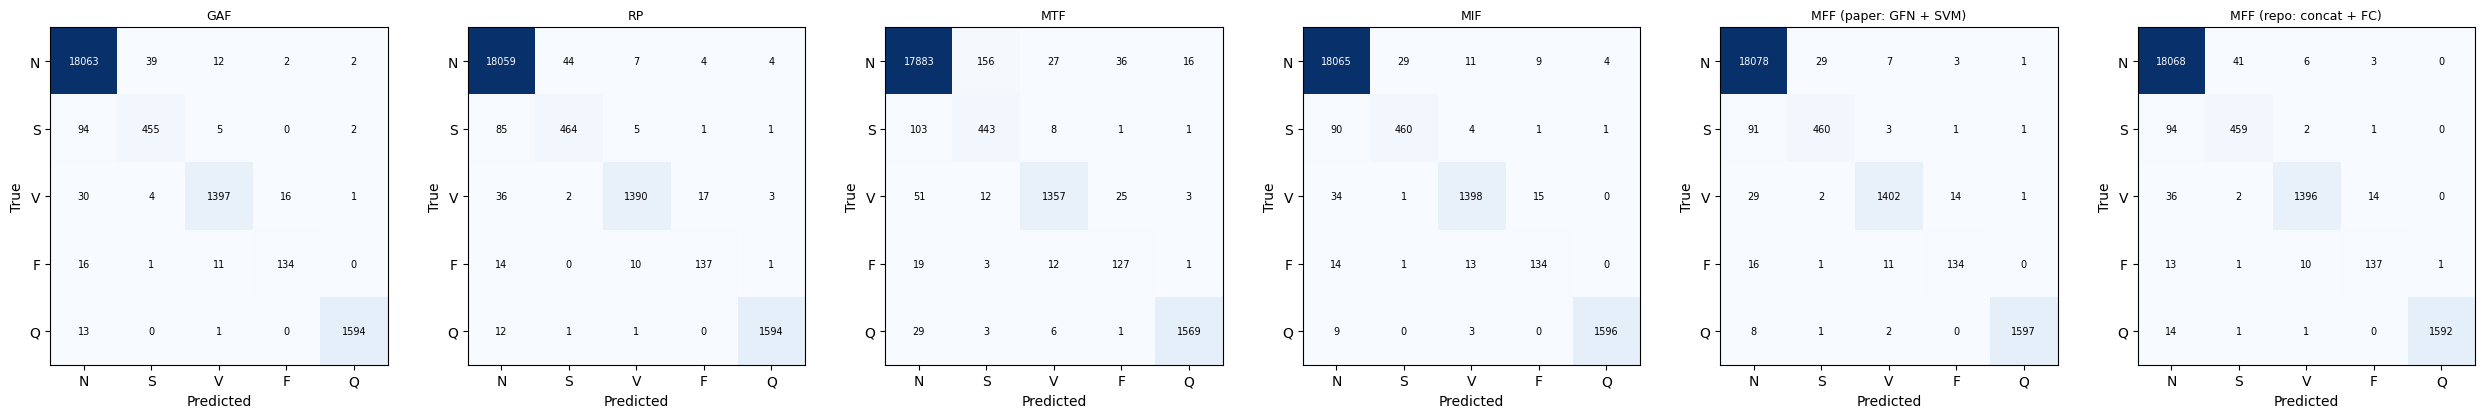

In [34]:
EVAL_SPECS = [
    # (label, nama file prediksi, tag checkpoint, kind, pembuat net, pembuat loader)
    ("GAF", "gaf_f1", "gaf", "f1", lambda: build_baseline()[0], lambda: gaf_test_loader),
    ("RP", "rp_f1", "rp", "f1", lambda: build_baseline()[0], lambda: rp_test_loader),
    ("MTF", "mtf_f1", "mtf", "f1", lambda: build_baseline()[0], lambda: mtf_test_loader),
    ("MIF", "mif_f1", "mif", "f1", lambda: build_baseline()[0], lambda: mif_test_loader),
]

results = {}
for label, name, tag, kind, make_net, make_loader in EVAL_SPECS:
    results[label] = evaluate_model(name, tag, kind, make_net, make_loader)

results["MFF (paper: GFN + SVM)"] = svm_metrics
results["MFF (repo: concat + FC)"] = evaluate_model(
    "mff_concat_f1", FC_TAG, "f1",
    make_net=lambda: build_fusion_head(FC_IN)[0],
    make_loader=lambda: mff_fc_test_loader,
) if mff_fc_test_loader is not None else None

NR = "NOT RUN"

# ---- Tabel A: checkpoint macro-F1 terbaik
table_a = pd.DataFrame(
    [
        {
            "method": label,
            "ckpt_epoch": NR if m is None else ("-" if m["epoch"] is None else m["epoch"]),
            "accuracy": NR if m is None else m["accuracy"],
            "macro_precision": NR if m is None else m["precision"],
            "macro_recall": NR if m is None else m["recall"],
            "macro_f1": NR if m is None else m["f1"],
        }
        for label, m in results.items()
    ]
)
print("TABEL A: checkpoint macro-F1 terbaik (seleksi pada test set)")
display(table_a.round(4))

# ---- Tabel B: epoch terakhir dari history (tanpa seleksi)
HISTORY_TAG = {"GAF": "gaf", "RP": "rp", "MTF": "mtf", "MIF": "mif", "MFF (repo: concat + FC)": "mff_concat"}
rows_b = []
for label in results:
    tag = HISTORY_TAG.get(label)
    if tag is not None and training_artifacts_valid(tag, HISTORY_EPOCHS[tag]):
        last = load_history(tag).iloc[-1]
        rows_b.append({
            "method": label, "epoch": int(last["epoch"]), "accuracy": last["test_accuracy"],
            "macro_precision": last["test_precision"], "macro_recall": last["test_recall"], "macro_f1": last["test_f1"],
        })
    else:
        rows_b.append({"method": label, "epoch": NR if tag is not None else "-", "accuracy": NR,
                       "macro_precision": NR, "macro_recall": NR, "macro_f1": NR})
table_b = pd.DataFrame(rows_b)
print("\nTABEL B: epoch terakhir (SVM tidak memiliki epoch; '-' = tidak berlaku)")
display(table_b.round(4))

# ---- Confusion matrix (metode yang sudah dijalankan)
available = {label: m for label, m in results.items() if m is not None}
if available:
    fig, axes = plt.subplots(1, len(available), figsize=(4.2 * len(available), 4), squeeze=False)
    for ax, (label, m) in zip(axes[0], available.items()):
        cm = confusion_matrix(m["y_true"], m["y_pred"], labels=range(5))
        ax.imshow(cm, cmap="Blues")
        ax.set_title(label, fontsize=9)
        ax.set_xticks(range(5)); ax.set_xticklabels(CLASS_NAMES)
        ax.set_yticks(range(5)); ax.set_yticklabels(CLASS_NAMES)
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        for i in range(5):
            for j in range(5):
                ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7,
                        color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.tight_layout()
    plt.show()


# 21. Comparison with Paper

**Sumber nilai paper:**
- Abstrak: **99,7 %** akurasi klasifikasi aritmia MIT-BIH (5 kelas AAMI EC57).
- Nilai per metode: **TABEL 5** paper (MIT-BIH, **AlexNet 227×227**), diisi dari angka yang diberikan pengguna. Angka ini belum diverifikasi ulang terhadap PDF paper oleh notebook ini (PDF tidak dapat diakses saat penyusunan).
- `MFF (repo: concat + FC)` tetap `NOT FILLED`: itu bukan metode Proposed MFF pada Tabel 5.

**Perbandingan bukan konfigurasi identik:** paper memakai AlexNet 227×227, sedangkan notebook ini memakai ResNet18 224×224 mengikuti repositori (ditambah perbedaan GAF/RP/MTF/MFF pada tabel di bawah). Selisih tidak boleh dibaca sebagai replikasi murni berhasil atau gagal.

Selisih ditampilkan apa adanya (poin persentase, hasil kita − paper); tidak ada klaim "sama dengan paper" kecuali angkanya memang demikian.

In [35]:
PAPER_ABSTRACT_ACCURACY = 0.997  # Abstrak: "classification accuracy of 99.7% ... on arrhythmia" (MIT-BIH)

# Nilai paper per metode: TABEL 5 (MIT-BIH, AlexNet 227x227), diisi dari angka yang diberikan pengguna.
# CATATAN: paper = AlexNet 227x227; notebook reproduksi ini = ResNet18 224x224 (mengikuti repo),
# sehingga perbandingan BUKAN konfigurasi identik.
PAPER_BY_METHOD = {
    "GAF": {"accuracy": 0.973, "precision": 0.85, "recall": 0.91},
    "RP": {"accuracy": 0.972, "precision": 0.82, "recall": 0.93},
    "MTF": {"accuracy": 0.915, "precision": 0.86, "recall": 0.89},
    "MIF": {"accuracy": 0.986, "precision": 0.93, "recall": 0.92},
    "MFF (paper: GFN + SVM)": {"accuracy": 0.997, "precision": 0.98, "recall": 0.98},
    "MFF (repo: concat + FC)": None,  # bukan "Proposed MFF" di Tabel 5 -> tetap NOT FILLED
}

NF = "NOT FILLED"
rows_c = []

# (1) Satu-satunya angka paper yang terverifikasi: akurasi terbaik pada abstrak
ours = {label: m["accuracy"] for label, m in results.items() if m is not None}
if ours:
    best_label = max(ours, key=ours.get)
    rows_c.append({
        "pembanding": "Terbaik (abstrak paper) vs hasil terbaik kita", "metode_kita": best_label,
        "paper_accuracy": PAPER_ABSTRACT_ACCURACY, "our_accuracy": ours[best_label],
        "selisih_pp": 100 * (ours[best_label] - PAPER_ABSTRACT_ACCURACY),
    })
else:
    rows_c.append({"pembanding": "Terbaik (abstrak paper) vs hasil terbaik kita", "metode_kita": NR,
                   "paper_accuracy": PAPER_ABSTRACT_ACCURACY, "our_accuracy": NR, "selisih_pp": NR})

# (2) Per metode
for label, m in results.items():
    p = PAPER_BY_METHOD.get(label)
    our = NR if m is None else m["accuracy"]
    rows_c.append({
        "pembanding": label, "metode_kita": label,
        "paper_accuracy": NF if p is None else p["accuracy"], "our_accuracy": our,
        "selisih_pp": NF if p is None else (NR if m is None else 100 * (m["accuracy"] - p["accuracy"])),
    })

comparison = pd.DataFrame(rows_c)
display(comparison.round(4))

# Perbedaan paper vs repositori vs notebook ini (diverifikasi dari teks paper dan kode repo)
differences = pd.DataFrame(
    [
        ("Backbone", "AlexNet (fc7 4096→512) dan CNN kecil", "ResNet18 pretrained; layer3-4 fine-tune; FC 512-256-128-5", "ResNet18 (repo)"),
        ("Ukuran input", "227×227 (AlexNet)", "224×224", "224×224"),
        ("GAF", "Summation (Eq. 2)", "Final: difference, image_size=150", "difference, 150 (repo)"),
        ("RP", "Threshold λ + Heaviside (Eq. 4)", "Non-biner: jarak/0.1, clip 10, d/5−1", "repo"),
        ("MTF", "10 bin kuantil (Eq. 5)", "get_mtf: 10 bin lebar-sama [0,1], skala r/5−1 → [−1,−0.8]", "repo"),
        ("MIF", "GAF-RP-MTF 3 channel → CNN → softmax", "HDF5 (N,3,224,224); contoh run 10 epoch", "tumpukan channel on-the-fly, 25 epoch"),
        ("MFF", "fc7 tiap modalitas → GFN → SVM", "Concat GAF+RP (1024-d) → FC 4 layer; tanpa GFN/SVM/MTF", "keduanya: GFN+SVM dan concat+FC"),
        ("GFN", "High-boost K (c=1), sigmoid, ⊙, Σ", "tidak ada", "sesuai paper; reshape 16×32 = asumsi"),
        ("SVM", "f = Wx + b; parameter tidak disebut", "tidak ada", "LinearSVC default = asumsi"),
        ("Split data / SMOTE", "MIT-BIH split Kaggle; SMOTE", "sama", "sama"),
        ("Seleksi checkpoint", "tidak dinyatakan", "terbaik pada test set (recall/F1)", "sama (test set)"),
        ("Bug repo yang dihindari", "-", "zip loader GAF shuffle=True dgn RP shuffle=False; ekstraktor tanpa .eval(); net[6] tidak di optimizer", "diperbaiki"),
    ],
    columns=["aspek", "paper", "repositori", "notebook ini"],
)
print("\nPerbedaan terverifikasi (paper vs repositori vs notebook ini):")
display(differences)
print("Catatan: penyebab numerik selisih tidak dapat dipisahkan tanpa ablation; daftar di atas adalah perbedaan "
      "yang terverifikasi, bukan penjelasan kausal.")


,pembanding,metode_kita,paper_accuracy,our_accuracy,selisih_pp
0,Terbaik (abstrak paper) vs hasil terbaik kita,MFF (paper: GFN + SVM),0.997,0.9899,-0.709501
1,GAF,GAF,0.973,0.9886,1.562598
2,RP,RP,0.972,0.9887,1.667166
3,MTF,MTF,0.915,0.9766,6.156678
4,MIF,MIF,0.986,0.9891,0.308277
5,MFF (paper: GFN + SVM),MFF (paper: GFN + SVM),0.997,0.9899,-0.709501
6,MFF (repo: concat + FC),MFF (repo: concat + FC),NOT FILLED,0.9890,NOT FILLED



Perbedaan terverifikasi (paper vs repositori vs notebook ini):


,aspek,paper,repositori,notebook ini
0,Backbone,AlexNet (fc7 4096→512) dan CNN kecil,ResNet18 pretrained; layer3-4 fine-tune; FC 51...,ResNet18 (repo)
1,Ukuran input,227×227 (AlexNet),224×224,224×224
2,GAF,Summation (Eq. 2),"Final: difference, image_size=150","difference, 150 (repo)"
3,RP,Threshold λ + Heaviside (Eq. 4),"Non-biner: jarak/0.1, clip 10, d/5−1",repo
4,MTF,10 bin kuantil (Eq. 5),"get_mtf: 10 bin lebar-sama [0,1], skala r/5−1 ...",repo
5,MIF,GAF-RP-MTF 3 channel → CNN → softmax,"HDF5 (N,3,224,224); contoh run 10 epoch","tumpukan channel on-the-fly, 25 epoch"
6,MFF,fc7 tiap modalitas → GFN → SVM,Concat GAF+RP (1024-d) → FC 4 layer; tanpa GFN...,keduanya: GFN+SVM dan concat+FC
7,GFN,"High-boost K (c=1), sigmoid, ⊙, Σ",tidak ada,sesuai paper; reshape 16×32 = asumsi
8,SVM,f = Wx + b; parameter tidak disebut,tidak ada,LinearSVC default = asumsi
9,Split data / SMOTE,MIT-BIH split Kaggle; SMOTE,sama,sama


Catatan: penyebab numerik selisih tidak dapat dipisahkan tanpa ablation; daftar di atas adalah perbedaan yang terverifikasi, bukan penjelasan kausal.


# 22. Save Results

Menulis ke `outputs/results/` (dan figure ke `outputs/figures/`). **Tidak** menimpa atau menghapus `summary_metrics.csv`, `history_*.csv`, checkpoint, atau HDF5 yang sudah ada: hanya file baru berikut yang ditulis ulang: `final_results_*.csv`, `paper_comparison.csv`, `confusion_*.csv`, `experiment_manifest.json`.

In [36]:
FIGURES_DIR = os.path.join(BASE_DIR, "outputs", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

table_a.to_csv(os.path.join(RESULTS_DIR, "final_results_ckpt_f1.csv"), index=False)
table_b.to_csv(os.path.join(RESULTS_DIR, "final_results_final_epoch.csv"), index=False)
comparison.to_csv(os.path.join(RESULTS_DIR, "paper_comparison.csv"), index=False)
differences.to_csv(os.path.join(RESULTS_DIR, "paper_repo_differences.csv"), index=False)

# confusion matrix (CSV) per metode yang sudah dijalankan; prediksi sudah tersimpan sebagai predictions_*.npz
for label, m in results.items():
    if m is None:
        continue
    cm = confusion_matrix(m["y_true"], m["y_pred"], labels=range(5))
    safe = label.split(" (")[0] + ("_" + label.split("(")[1].split(":")[0] if "(" in label else "")
    pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(
        os.path.join(RESULTS_DIR, f"confusion_{safe.lower()}.csv")
    )

if available:
    fig.savefig(os.path.join(FIGURES_DIR, "confusion_matrices_all.png"), dpi=150, bbox_inches="tight")

flag_names = [
    "RUN_GAF_SMOKE", "RUN_GAF_FULL", "RUN_RP_SMOKE", "RUN_RP_FULL", "RUN_MTF",
    "RUN_MTF_SMOKE", "RUN_MTF_FULL", "RUN_MIF_SMOKE", "RUN_MIF_FULL", "RUN_MFF",
]
artifact_paths = [GAF_H5, RP_H5, MTF_H5, *FEATURE_PATHS.values(), SVM_MODEL_PATH,
                  *[mff_feature_path(t) for t in FEATURE_SOURCES],
                  *[ckpt_path(t, k) for t in ("gaf", "rp", "mtf", "mif", FC_TAG) for k in ("recall", "f1")],
                  *[history_path(t) for t in ("gaf", "rp", "mtf", "mif", FC_TAG)]]

manifest = {
    "seed": SEED,
    "torch": torch.__version__,
    "device": str(DEVICE),
    "flags": {k: globals().get(k) for k in flag_names},
    "n_train": N_TRAIN, "n_test": N_TEST,
    "epochs": {"cnn_full": NUM_EPOCHS_FULL, "mff_head": NUM_EPOCHS_MFF_HEAD},
    "fusion_checkpoint_kind": FUSION_CKPT_KIND,
    "checkpoint_meta": {
        f"{t}/{k}": read_ckpt_meta(t, k)
        for t in ("gaf", "rp", "mtf", "mif", FC_TAG) for k in ("recall", "f1") if os.path.exists(ckpt_path(t, k))
    },
    "artifacts": {os.path.relpath(p, BASE_DIR): os.path.exists(p) for p in artifact_paths},
    "assumptions": {
        "gfn_map_shape": list(GFN_MAP_SHAPE),
        "svm": "LinearSVC(C=1.0, dual=False), tanpa normalisasi",
        "paper_values": "abstrak (99.7%) + Tabel 5 per metode (AlexNet 227x227, diberikan pengguna; bukan konfigurasi identik); MFF repo: NOT FILLED",
    },
    "results_ckpt_f1": {k: (None if m is None else {x: float(m[x]) for x in ("accuracy", "precision", "recall", "f1")})
                        for k, m in results.items()},
}
with open(os.path.join(RESULTS_DIR, "experiment_manifest.json"), "w") as fh:
    json.dump(manifest, fh, indent=2)

print("Tersimpan di:", RESULTS_DIR)
print(sorted(f for f in os.listdir(RESULTS_DIR) if f.startswith(("final_", "paper_", "confusion_", "experiment_", "predictions_"))))


Tersimpan di: /content/drive/MyDrive/Projek PSD/ECG_Multimodal_Fusion/outputs/results
['confusion_gaf.csv', 'confusion_mff_paper.csv', 'confusion_mff_repo.csv', 'confusion_mif.csv', 'confusion_mtf.csv', 'confusion_rp.csv', 'experiment_manifest.json', 'final_results_ckpt_f1.csv', 'final_results_final_epoch.csv', 'paper_comparison.csv', 'paper_repo_differences.csv', 'predictions_gaf_f1.npz', 'predictions_mff_concat_f1.npz', 'predictions_mff_gfn_svm.npz', 'predictions_mif_f1.npz', 'predictions_mtf_f1.npz', 'predictions_rp_f1.npz']
